# Gold Price Prediction: 25 Years of Daily Gold Futures

**Course:** Data Analysis 1 &nbsp;|&nbsp; **Lecturer:** Dr. HAS Sothea &nbsp;|&nbsp; **Semester:** Fall 2026

**Team:** Len Monireach (2024498) and Dy David (2024583)

This notebook holds the whole project: loading the data, cleaning it, exploring it, building the
models and scoring them. Every number and every chart in our report comes from a cell below.

**How to run it.** Put `gold_data_daily_comprehensive_cleaned.csv` in a `data/` folder next to this
notebook, then run all cells from top to bottom. A full run takes a few minutes. Charts are
saved to `figures/` and result tables to `results/`.

**The four questions we ask**

1. What does 25 years of daily gold data look like once it is cleaned (trend, risk, seasonality, anomalies)?
2. Can a model predict tomorrow's closing price better than simply repeating today's price?
3. Can a model predict whether tomorrow's price goes up or down?
4. If the direction cannot be predicted, can the *size* of tomorrow's move be predicted?

## 1. Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from IPython.display import display

from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEED = 42
rng = np.random.default_rng(SEED)

DATA_PATH = Path("data") / "gold_data_daily_comprehensive_cleaned.csv"
if not DATA_PATH.exists():                      # e.g. the file sits next to the notebook (Colab)
    DATA_PATH = Path("gold_data_daily_comprehensive_cleaned.csv")
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

RESULTS = {}          # every headline number goes in here and is written to results/metrics.json at the end

One chart style for the whole project. The colours come from a palette we checked for
colour-blind safety (blue, orange and aqua stay distinguishable under the common forms of colour
blindness). Blue means "the series we are talking about", grey means context, and blue against red
is only used for gains against losses.

In [2]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, CONTEXT = "#e1e0d9", "#c3c2b7", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
BLUE_DARK, BLUE_LIGHT = "#184f95", "#9ec5f4"
NEUTRAL = "#f0efec"

DIVERGING = LinearSegmentedColormap.from_list("loss_gain", [RED, NEUTRAL, BLUE])
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#3987e5", "#0d366b"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.max_open_warning": 0,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.titlecolor": INK,
    "axes.labelsize": 9, "axes.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "ytick.major.size": 0, "xtick.major.size": 3,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 1.6, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
    "text.color": INK,
})

dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")


def save(fig, name):
    """Save a figure to figures/<name>.png and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def note(ax, text, xy, xytext, ha="left", va="center"):
    """Small direct label with a thin leader line."""
    ax.annotate(text, xy=xy, xytext=xytext, textcoords="offset points", ha=ha, va=va,
                fontsize=8, color=INK_2,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6, shrinkA=0, shrinkB=2))

## 2. Loading the data and a first look

The file is the Kaggle dataset *Gold Price Historical Data (2000-2026)*. Each row is one trading day of
the gold futures price that Yahoo Finance publishes under the ticker `GC=F`.

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head(3))
display(raw.tail(3))

6,383 rows x 20 columns


,DateTime,Date,Year,Month,Day,DayOfWeek,Quarter,Open,High,Low,Close,Volume,Price_Change,Price_Change_Percent,MA_7,MA_30,MA_90,MA_365,Volatility_30d,Source
0,2000-08-30 00:00:00-04:00,2000-08-30,2000,8,30,Wednesday,3,273.9000,273.9000,273.9000,273.9000,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
1,2000-08-31 00:00:00-04:00,2000-08-31,2000,8,31,Thursday,3,274.8000,278.3000,274.8000,278.3000,0,4.4000,1.6064,NaN,NaN,NaN,NaN,NaN,Yahoo Finance
2,2000-09-01 00:00:00-04:00,2000-09-01,2000,9,1,Friday,3,277.0000,277.0000,277.0000,277.0000,0,-1.3000,-0.4671,NaN,NaN,NaN,NaN,NaN,Yahoo Finance


,DateTime,Date,Year,Month,Day,DayOfWeek,Quarter,Open,High,Low,Close,Volume,Price_Change,Price_Change_Percent,MA_7,MA_30,MA_90,MA_365,Volatility_30d,Source
6380,2026-02-04 00:00:00-05:00,2026-02-04,2026,2,4,Wednesday,1,"4,923.2998","5,082.2002","4,897.8999","4,920.3999",3886,16.6997,0.3406,"4,980.0571","4,667.3900","4,288.0544","3,327.8682",2.9614,Yahoo Finance
6381,2026-02-05 00:00:00-05:00,2026-02-05,2026,2,5,Thursday,1,"5,008.7002","5,012.2998","4,786.0000","4,861.3999",793,-59.0000,-1.1991,"4,948.8428","4,681.2833","4,300.1222","3,334.3148",2.9629,Yahoo Finance
6382,2026-02-06 00:00:00-05:00,2026-02-06,2026,2,6,Friday,1,"4,800.0000","4,995.6001","4,670.0000","4,979.7998",171364,118.3999,2.4355,"4,902.8714","4,697.8500","4,312.9989","3,341.0603",2.9862,Yahoo Finance


In [4]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
    "first_row": raw.iloc[0].astype(str).str.slice(0, 25),
    "last_row": raw.iloc[-1].astype(str).str.slice(0, 25),
})
display(overview)

n_numeric = raw.select_dtypes("number").shape[1]
print(f"Numeric columns: {n_numeric}   |   text columns: {raw.shape[1] - n_numeric}")
print(f"Fully duplicated rows: {raw.duplicated().sum()}   |   repeated dates: {raw['Date'].duplicated().sum()}")
print(f"Missing cells: {raw.isna().sum().sum()} of {raw.size:,} ({raw.isna().sum().sum() / raw.size:.2%})")

RESULTS["data"] = {
    "rows": int(raw.shape[0]), "cols": int(raw.shape[1]), "numeric_cols": int(n_numeric),
    "missing_cells": int(raw.isna().sum().sum()), "total_cells": int(raw.size),
    "missing_pct": float(raw.isna().sum().sum() / raw.size * 100),
    "duplicate_rows": int(raw.duplicated().sum()),
    "first_date": raw["Date"].iloc[0], "last_date": raw["Date"].iloc[-1],
}

,dtype,non_null,missing,unique_values,first_row,last_row
DateTime,str,6383,0,6383,2000-08-30 00:00:00-04:00,2026-02-06 00:00:00-05:00
Date,str,6383,0,6383,2000-08-30,2026-02-06
Year,int64,6383,0,27,2000,2026
Month,int64,6383,0,12,8,2
Day,int64,6383,0,31,30,6
DayOfWeek,str,6383,0,5,Wednesday,Friday
Quarter,int64,6383,0,4,3,1
Open,float64,6383,0,5075,273.8999938964844,4800.0
High,float64,6383,0,5059,273.8999938964844,4995.60009765625
Low,float64,6383,0,5023,273.8999938964844,4670.0


Numeric columns: 16   |   text columns: 4
Fully duplicated rows: 0   |   repeated dates: 0
Missing cells: 520 of 127,660 (0.41%)


In [5]:
display(raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
Year,"6,383.0000","2,012.9002",7.3408,"2,000.0000","2,007.0000","2,013.0000","2,019.0000","2,026.0000"
Month,"6,383.0000",6.5690,3.4439,1.0000,4.0000,7.0000,10.0000,12.0000
Day,"6,383.0000",15.7108,8.7526,1.0000,8.0000,16.0000,23.0000,31.0000
Quarter,"6,383.0000",2.5231,1.1185,1.0000,2.0000,3.0000,4.0000,4.0000
Open,"6,383.0000","1,265.3208",760.0857,255.0000,650.4000,"1,250.3000","1,689.6000","5,415.7002"
High,"6,383.0000","1,272.0572",765.7083,256.1000,652.9000,"1,255.5000","1,701.7000","5,586.2002"
Low,"6,383.0000","1,258.4120",754.4970,255.0000,648.4000,"1,243.7000","1,674.8500","5,301.6001"
Close,"6,383.0000","1,265.3739",760.2677,255.1000,650.9000,"1,250.2000","1,688.5500","5,318.3999"
Volume,"6,383.0000","4,315.0266","24,170.7798",0.0000,23.0000,117.0000,449.0000,"386,334.0000"
Price_Change,"6,382.0000",0.7374,19.0636,-604.5000,-4.8000,0.5000,6.5000,281.2002


**What we see.** 6,383 trading days and 20 columns, from 30 August 2000 to 6 February 2026. Four
columns hold the daily prices (Open, High, Low, Close) and one the traded volume. Seven are calendar
fields. Seven were calculated from Close by whoever built the dataset (price change, moving averages,
volatility). `Source` says "Yahoo Finance" on every row.

No duplicated rows. Missing values exist but are rare (0.41% of all cells), and they sit only in the
calculated columns. We come back to them in section 3.6 once we understand how those columns were made.

## 3. Data preprocessing

The file is called "cleaned", but we did not take that on trust. This section checks every column
against what it claims to be, and the checks turned up four problems that a quick `df.info()` would
never show.

### 3.1 Dates and redundant columns

In [6]:
df = raw.copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()

calendar_checks = pd.Series({
    "Year": (df["Year"] == df.index.year).all(),
    "Month": (df["Month"] == df.index.month).all(),
    "Day": (df["Day"] == df.index.day).all(),
    "DayOfWeek": (df["DayOfWeek"] == df.index.day_name()).all(),
    "Quarter": (df["Quarter"] == df.index.quarter).all(),
}, name="identical to value derived from Date")
display(calendar_checks.to_frame())

print("DateTime, date part equals Date on every row:", (raw["DateTime"].str[:10] == raw["Date"]).all())
print("DateTime, clock times found:", raw["DateTime"].str[11:19].unique().tolist())
print("DateTime, UTC offsets found:", raw["DateTime"].str[-6:].value_counts().to_dict())
print("Source, distinct values:", raw["Source"].unique().tolist())
print("Rows in date order:", df.index.is_monotonic_increasing, "| weekend rows:", int((df.index.dayofweek >= 5).sum()))

,identical to value derived from Date
Year,True
Month,True
Day,True
DayOfWeek,True
Quarter,True


DateTime, date part equals Date on every row: True
DateTime, clock times found: ['00:00:00']
DateTime, UTC offsets found: {'-04:00': 4051, '-05:00': 2332}
Source, distinct values: ['Yahoo Finance']
Rows in date order: True | weekend rows: 0


Seven of the 20 columns carry no information of their own:

* `Year`, `Month`, `Day`, `DayOfWeek` and `Quarter` match the values we derive from `Date` on all 6,383 rows.
* `DateTime` is `Date` with a midnight timestamp. The only thing it adds is the New York UTC offset
  (-04:00 in summer, -05:00 in winter), which is daylight saving time and has nothing to do with gold.
* `Source` has one value.

We drop `DateTime` and `Source`, use `Date` as the index, and keep the calendar fields only because they
are handy for grouping in the EDA.

In [7]:
df = df.drop(columns=["DateTime", "Source"])

### 3.2 Are the calculated columns what their names say?

We recompute each derived column from `Close` and compare it with the column in the file.

In [8]:
close = df["Close"]
recomputed = {
    "Price_Change": close.diff(),
    "Price_Change_Percent": close.pct_change(fill_method=None) * 100,
    "MA_7": close.rolling(7).mean(),
    "MA_30": close.rolling(30).mean(),
    "MA_90": close.rolling(90).mean(),
    "MA_365": close.rolling(365).mean(),
    "Volatility_30d": df["Price_Change_Percent"].rolling(30).std(),
}
definitions = {
    "Price_Change": "Close(t) - Close(t-1)",
    "Price_Change_Percent": "100 x (Close(t) / Close(t-1) - 1)",
    "MA_7": "mean of the last 7 closes",
    "MA_30": "mean of the last 30 closes",
    "MA_90": "mean of the last 90 closes",
    "MA_365": "mean of the last 365 closes",
    "Volatility_30d": "sample std of the last 30 values of Price_Change_Percent",
}
derived_audit = pd.DataFrame({
    "definition_that_reproduces_it": definitions,
    "largest_abs_difference": {c: float((df[c] - s).abs().max()) for c, s in recomputed.items()},
    "missing_in_file": {c: int(df[c].isna().sum()) for c in recomputed},
    "missing_when_recomputed": {c: int(s.isna().sum()) for c, s in recomputed.items()},
})
pd.set_option("display.float_format", lambda v: f"{v:.2e}")
display(derived_audit)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
derived_audit.to_csv(RES_DIR / "derived_column_audit.csv")

span_years = 365 / (len(df) / ((df.index[-1] - df.index[0]).days / 365.25))
print(f"Trading days per calendar year in this file: {len(df) / ((df.index[-1] - df.index[0]).days / 365.25):.1f}")
print(f"So a 365-row window covers about {span_years:.2f} calendar years, not one.")
RESULTS["data"]["trading_days_per_year"] = float(len(df) / ((df.index[-1] - df.index[0]).days / 365.25))
RESULTS["data"]["ma365_span_years"] = float(span_years)

,definition_that_reproduces_it,largest_abs_difference,missing_in_file,missing_when_recomputed
Price_Change,Close(t) - Close(t-1),2.27e-13,1,1
Price_Change_Percent,100 x (Close(t) / Close(t-1) - 1),3.33e-14,1,1
MA_7,mean of the last 7 closes,9.09e-13,6,6
MA_30,mean of the last 30 closes,9.09e-13,29,29
MA_90,mean of the last 90 closes,9.09e-13,89,89
MA_365,mean of the last 365 closes,4.55e-13,364,364
Volatility_30d,sample std of the last 30 values of Price_Chan...,1.29e-14,30,30


Trading days per calendar year in this file: 250.9
So a 365-row window covers about 1.45 calendar years, not one.


All seven columns reproduce to within floating-point rounding (differences below 0.000000000001), and the
missing values fall on the same rows. Two details matter later:

* **The windows count rows, not calendar days.** The file has about 251 trading days per year, so
  `MA_365` averages roughly 1.45 years of prices and `Volatility_30d` covers about six weeks. The
  names suggest "one year" and "one month". They are neither.
* **`Volatility_30d` is a daily figure.** It is the standard deviation of daily percentage changes,
  not an annualised volatility. A value of 1.0 means a typical daily move of about 1%.

### 3.3 Price integrity: does every bar make sense?

For a valid daily bar, Low <= Open, Close <= High. We test that, and we count bars where nothing
traded.

In [9]:
ohlc = df[["Open", "High", "Low", "Close"]]
close_above_high = df["Close"] > df["High"]
close_below_low = df["Close"] < df["Low"]
open_outside = (df["Open"] > df["High"]) | (df["Open"] < df["Low"])
flat_bar = (df["Open"] == df["High"]) & (df["High"] == df["Low"]) & (df["Low"] == df["Close"])
zero_volume = df["Volume"] == 0

integrity = pd.Series({
    "Close above High": int(close_above_high.sum()),
    "Close below Low": int(close_below_low.sum()),
    "Close outside [Low, High] (either)": int((close_above_high | close_below_low).sum()),
    "Open outside [Low, High]": int(open_outside.sum()),
    "Flat bar: Open = High = Low = Close": int(flat_bar.sum()),
    "High equals Low": int((df["High"] == df["Low"]).sum()),
    "Zero volume": int(zero_volume.sum()),
    "Close unchanged from previous day": int((df["Price_Change"] == 0).sum()),
    "Zero or negative price": int((ohlc <= 0).sum().sum()),
}, name="rows")
integrity_table = integrity.to_frame()
integrity_table["share_of_rows_%"] = (integrity / len(df) * 100).round(2)
display(integrity_table)
integrity_table.to_csv(RES_DIR / "integrity_checks.csv")

quality_by_year = pd.DataFrame({
    "Flat bars (O = H = L = C)": flat_bar,
    "Close outside Low-High range": close_above_high | close_below_low,
    "Zero volume": zero_volume,
}).groupby(df.index.year).mean() * 100
display(quality_by_year.round(1).T)
quality_by_year.to_csv(RES_DIR / "quality_by_year.csv")

last_violation = df.index[close_above_high | close_below_low].max()
print("Last day with Close outside the Low-High range:", last_violation.date())
RESULTS["integrity"] = {k: int(v) for k, v in integrity.items()}
RESULTS["integrity"]["last_close_outside_range"] = str(last_violation.date())
RESULTS["integrity"]["flat_share_2000_2007"] = float(flat_bar[:"2007"].mean() * 100)
RESULTS["integrity"]["flat_share_2008_on"] = float(flat_bar["2008":].mean() * 100)

,rows,share_of_rows_%
Close above High,223,3.4900
Close below Low,207,3.2400
"Close outside [Low, High] (either)",430,6.7400
"Open outside [Low, High]",56,0.8800
Flat bar: Open = High = Low = Close,812,12.7200
High equals Low,1040,16.2900
Zero volume,418,6.5500
Close unchanged from previous day,45,0.7000
Zero or negative price,0,0.0000


Date,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Flat bars (O = H = L = C),52.4000,47.4000,38.0000,27.6000,21.3000,31.9000,29.2000,26.2000,3.2000,2.0000,14.3000,0.8000,0.4000,1.6000,6.3000,0.4000,2.4000,4.4000,14.0000,11.1000,1.6000,4.4000,5.2000,5.6000,5.2000,2.4000,8.0000
Close outside Low-High range,0.0000,0.4000,0.0000,20.4000,34.5000,25.0000,32.8000,28.2000,17.0000,3.6000,2.0000,7.9000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Zero volume,45.2000,42.1000,32.8000,10.0000,8.0000,19.4000,13.2000,11.1000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4000,1.2000,0.0000,0.0000,0.4000,7.2000,3.6000,0.0000,0.4000,0.4000,0.4000,0.0000,2.0000,0.0000


Last day with Close outside the Low-High range: 2011-11-14


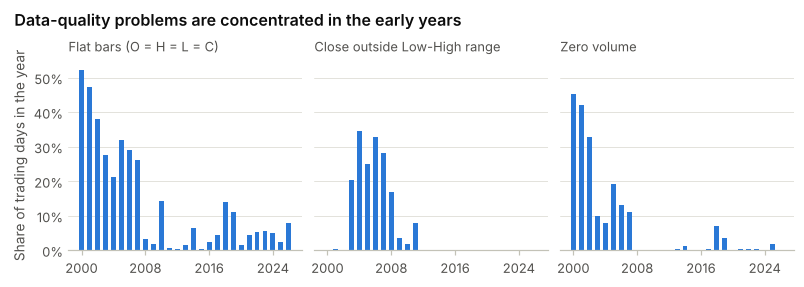

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), sharey=True, constrained_layout=True)
for ax, col in zip(axes, quality_by_year.columns):
    ax.bar(quality_by_year.index, quality_by_year[col], width=0.62, color=BLUE)
    ax.set_title(col, fontsize=8.5, fontweight="normal", color=INK_2, pad=6)
    ax.set_xticks([2000, 2008, 2016, 2024])
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
axes[0].set_ylabel("Share of trading days in the year")
fig.suptitle("Data-quality problems are concentrated in the early years", x=0.01, ha="left",
             fontsize=10.5, fontweight="semibold")
save(fig, "fig01_data_quality_by_year")

**Three findings.**

1. **430 rows have a Close outside the day's own Low-High range**, which is impossible for traded
   prices. They all fall between 2001 and 2011. The cause is how futures are quoted: Close is the
   exchange's official *settlement* price, while Open, High and Low come from actual trades. In a
   thinly traded contract the two can disagree.
2. **812 rows (12.7%) are flat bars** where all four prices are equal, and 418 rows report zero
   volume. Before 2008 between a fifth and a half of each year's bars are flat.
3. No price is zero or negative, and only 45 days repeat the previous close.

**Decision.** We trust `Close`, because the settlement price is the official one and it is what the
derived columns are built from. We do not trust `Open`, `High` and `Low` in the early years. We repair
them the standard way, by widening the range so that it contains Open and Close, and we build almost
all model features from `Close` alone.

In [11]:
df["High"] = ohlc.max(axis=1)
df["Low"] = ohlc.min(axis=1)
repaired = int(((df["High"] != ohlc["High"]) | (df["Low"] != ohlc["Low"])).sum())
print(f"Rows where High or Low was widened: {repaired}")
print("Remaining violations:", int(((df['Close'] > df['High']) | (df['Close'] < df['Low']) |
                                     (df['Open'] > df['High']) | (df['Open'] < df['Low'])).sum()))
RESULTS["integrity"]["rows_repaired"] = repaired

Rows where High or Low was widened: 441
Remaining violations: 0


### 3.4 Is the calendar complete?

A time series can be "complete" in every column and still have whole days missing. We list every
weekday between the first and last date that has no row and try to explain each one.

In [12]:
from pandas.tseries.holiday import GoodFriday, USFederalHolidayCalendar

start, end = df.index.min(), df.index.max()
weekdays = pd.bdate_range(start, end)
absent = weekdays.difference(df.index)
federal = USFederalHolidayCalendar().holidays(start, end)
good_fridays = GoodFriday.dates(start, end)
closures = pd.to_datetime(["2001-09-11", "2001-09-12", "2001-09-13",     # after the 11 September attacks
                           "2004-06-11", "2018-12-05",                    # national days of mourning
                           "2012-10-29", "2012-10-30"])                   # Hurricane Sandy


def explain(day):
    if day in federal:
        return "US federal holiday"
    if day in good_fridays:
        return "Good Friday"
    if day in closures:
        return "Known market closure"
    if (day - pd.offsets.BDay(1)) in federal or (day + pd.offsets.BDay(1)) in federal:
        return "Day next to a federal holiday"
    return "No explanation found"


absent_reason = pd.Series([explain(d) for d in absent], index=absent)
calendar_table = absent_reason.value_counts().rename("weekdays_without_a_row").to_frame()
display(calendar_table)
print("Unexplained gaps:", [d.strftime("%Y-%m-%d") for d in absent_reason[absent_reason == "No explanation found"].index])
print(f"Weekdays in range: {len(weekdays):,} | rows present: {len(df):,} | absent: {len(absent)}")
print("Federal holidays on which the market traded and a row exists:", len(df.index.intersection(federal)))
gap_days = df.index.to_series().diff().dt.days
print("Longest gap between consecutive rows:", int(gap_days.max()), "calendar days")

unexplained = int((absent_reason == "No explanation found").sum())
RESULTS["calendar"] = {
    "weekdays": int(len(weekdays)), "absent": int(len(absent)), "unexplained": unexplained,
    "by_reason": {k: int(v) for k, v in absent_reason.value_counts().items()},
    "unexplained_dates": [d.strftime("%Y-%m-%d") for d in absent_reason[absent_reason == "No explanation found"].index],
    "completeness_pct": float(len(df) / (len(df) + unexplained) * 100),
    "max_gap_days": int(gap_days.max()),
}
calendar_table.to_csv(RES_DIR / "calendar_gaps.csv")

,weekdays_without_a_row
US federal holiday,207
Good Friday,25
Day next to a federal holiday,11
Known market closure,7
No explanation found,5


Unexplained gaps: ['2005-03-30', '2005-04-28', '2005-06-29', '2006-11-27', '2018-01-29']
Weekdays in range: 6,638 | rows present: 6,383 | absent: 255
Federal holidays on which the market traded and a row exists: 55
Longest gap between consecutive rows: 5 calendar days


255 weekdays have no row, and all but five are explained by holidays or known closures (11 to 13
September 2001, Hurricane Sandy in 2012, and two national days of mourning). The five
single days we could not explain make the series 99.9% complete, and the longest gap between two rows
is five calendar days.

**Decision.** We do not insert rows or forward-fill prices for closed days. The market was shut, so
there was no price. We treat the file as a sequence of trading days, which is also how the
moving-average columns were built.

### 3.5 Volume does not measure what it seems to

In [13]:
vol = df["Volume"]
display(vol.describe(percentiles=[0.5, 0.9, 0.99]).to_frame().T)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
volume_by_month = vol.groupby(df.index.month).agg(["mean", "median"])
volume_by_month.index = month_names
late = df.index.day >= 25
volume_by_part = pd.DataFrame({
    "days 1-24": vol[~late].groupby(df.index.month[~late]).mean(),
    "days 25-31": vol[late].groupby(df.index.month[late]).mean(),
})
volume_by_part.index = month_names
display(volume_by_month.round(0).T)
display(volume_by_part.round(0).T)

top_volume = df.nlargest(10, "Volume")[["Close", "Volume"]]
display(top_volume)

busy = ["Jan", "Mar", "May", "Jul", "Nov"]
RESULTS["volume"] = {
    "median": float(vol.median()), "mean": float(vol.mean()), "max": int(vol.max()),
    "p99": float(vol.quantile(0.99)),
    "mean_busy_months": float(volume_by_month.loc[busy, "mean"].mean()),
    "mean_other_months": float(volume_by_month.drop(busy)["mean"].mean()),
    "mean_days_25_31": float(vol[late].mean()), "mean_days_1_24": float(vol[~late].mean()),
    "top10_all_after_day_24": bool((top_volume.index.day >= 25).all()),
    "top10_months": sorted(set(int(m) for m in top_volume.index.month)),
}

,count,mean,std,min,50%,90%,99%,max
Volume,"6,383.0000","4,315.0266","24,170.7798",0.0000,117.0000,"1,601.6000","150,979.4000","386,334.0000"


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
mean,"9,678.0000",955.0000,"7,714.0000",474.0000,"10,143.0000",452.0000,"9,142.0000",492.0000,"1,018.0000",261.0000,"11,210.0000",503.0000
median,47.0000,319.0000,58.0000,238.0000,30.0000,214.0000,41.0000,242.0000,46.0000,103.0000,34.0000,251.0000


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
days 1-24,169.0000,"1,043.0000",153.0000,517.0000,118.0000,490.0000,102.0000,519.0000,116.0000,275.0000,561.0000,560.0000
days 25-31,"39,016.0000",488.0000,"35,010.0000",308.0000,"53,251.0000",303.0000,"38,284.0000",401.0000,"4,368.0000",214.0000,"60,447.0000",263.0000


,Close,Volume
Date,,
2018-05-29,"1,298.7000",386334
2019-11-26,"1,459.8000",346362
2018-03-27,"1,341.3000",290889
2018-01-26,"1,351.6000",280546
2012-11-28,"1,716.5000",276136
2017-11-28,"1,294.7000",275442
2017-05-26,"1,267.6000",271457
2012-05-29,"1,548.6000",259050
2018-07-27,"1,222.6000",254428


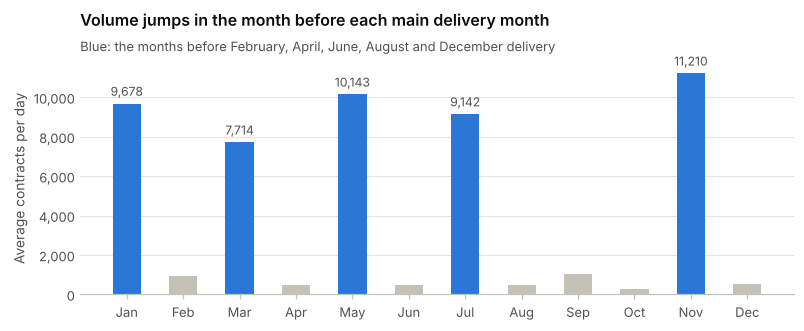

In [14]:
fig, ax = plt.subplots(figsize=(7.2, 2.9), constrained_layout=True)
colors = [BLUE if m in busy else CONTEXT for m in month_names]
ax.bar(month_names, volume_by_month["mean"], width=0.5, color=colors)
for m in busy:
    ax.text(month_names.index(m), volume_by_month.loc[m, "mean"] + 250, f"{volume_by_month.loc[m, 'mean']:,.0f}",
            ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_ylabel("Average contracts per day")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Volume jumps in the month before each main delivery month", pad=24)
ax.text(0, 1.035, "Blue: the months before February, April, June, August and December delivery",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5, color=INK_2)
save(fig, "fig02_volume_by_month")

The median day trades 117 contracts and the busiest trades 386,334. Investor excitement does not explain
a gap that size. Average volume in January, March, May, July and November is sixteen times the average of
the other months, the surge sits in the last few days of those months, and all ten record days fall on or
after the 26th.

The pattern fits the contract calendar. `GC=F` follows the *front-month* contract, the one closest to
delivery. Most of the time that is a quiet contract. When it rolls onto one of the main delivery months
(February, April, June, August, December) the series briefly points at the contract everyone trades.

**Decision.** In this file `Volume` records which contract the ticker is tracking, not how busy the
gold market is. We leave it out of the models.

### 3.6 Missing values

Now that we know how the derived columns were calculated, the missing values are easy to read.

In [15]:
windows = {"Price_Change": 1, "Price_Change_Percent": 1, "MA_7": 7, "MA_30": 30, "MA_90": 90,
           "MA_365": 365, "Volatility_30d": 30}
missing = df.isna().sum()
missing = missing[missing > 0]
missing_table = pd.DataFrame({
    "missing_rows": missing,
    "share_of_rows_%": (missing / len(df) * 100).round(2),
    "window_length": pd.Series(windows),
    "first_valid_date": {c: df[c].first_valid_index().date() for c in missing.index},
    "all_missing_rows_at_the_start": {c: bool(df[c].isna().to_numpy()[: missing[c]].all()) for c in missing.index},
}).loc[missing.index]
display(missing_table)
missing_table.to_csv(RES_DIR / "missing_values.csv")

rows_with_gap = int(df.isna().any(axis=1).sum())
print(f"Rows with at least one missing value: {rows_with_gap} ({rows_with_gap / len(df):.2%}); "
      f"they are rows 1 to {rows_with_gap}, ending {df.index[rows_with_gap - 1].date()}")
print(f"Missing values in Open/High/Low/Close/Volume: {int(df[['Open', 'High', 'Low', 'Close', 'Volume']].isna().sum().sum())}")

RESULTS["missing"] = {
    "by_column": {c: int(v) for c, v in missing.items()},
    "rows_with_any": rows_with_gap, "rows_with_any_pct": float(rows_with_gap / len(df) * 100),
    "last_incomplete_date": str(df.index[rows_with_gap - 1].date()),
    "first_complete_date": str(df.index[rows_with_gap].date()),
}

,missing_rows,share_of_rows_%,window_length,first_valid_date,all_missing_rows_at_the_start
Price_Change,1,0.0200,1,2000-08-31,True
Price_Change_Percent,1,0.0200,1,2000-08-31,True
MA_7,6,0.0900,7,2000-09-08,True
MA_30,29,0.4500,30,2000-10-11,True
MA_90,89,1.3900,90,2001-01-09,True
MA_365,364,5.7000,365,2002-02-20,True
Volatility_30d,30,0.4700,30,2000-10-12,True


Rows with at least one missing value: 364 (5.70%); they are rows 1 to 364, ending 2002-02-19
Missing values in Open/High/Low/Close/Volume: 0


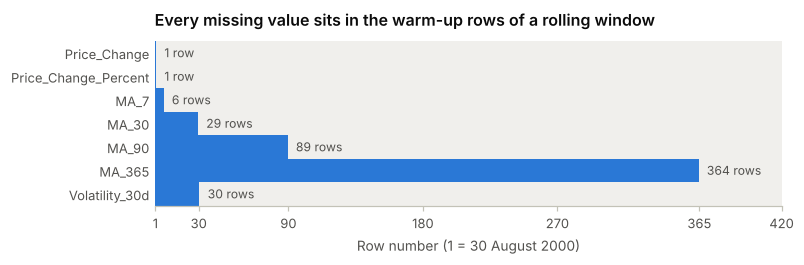

In [16]:
shown = 420
grid = df[list(missing.index)].isna().to_numpy()[:shown].T
fig, ax = plt.subplots(figsize=(7.2, 2.3), constrained_layout=True)
ax.imshow(grid, aspect="auto", interpolation="nearest", cmap=LinearSegmentedColormap.from_list("m", [NEUTRAL, BLUE]),
          extent=(0.5, shown + 0.5, len(missing) - 0.5, -0.5))
ax.set_yticks(range(len(missing)))
ax.set_yticklabels(missing.index)
ax.set_xlabel("Row number (1 = 30 August 2000)")
ax.set_xticks([1, 30, 90, 180, 270, 365, 420])
ax.grid(False)
for i, c in enumerate(missing.index):
    ax.text(missing[c] + 6, i, f"{missing[c]} row" + ("s" if missing[c] > 1 else ""), va="center", fontsize=8, color=INK_2)
ax.set_title("Every missing value sits in the warm-up rows of a rolling window")
save(fig, "fig03_missing_map")

**Why they are missing.** A 365-row average cannot exist until 365 rows have passed, so the first 364
values of `MA_365` are empty. The same holds for the other windows: 6 rows for `MA_7`, 29 for
`MA_30`, 89 for `MA_90`, 30 for `Volatility_30d` and one for the price change. Nothing is missing after
the warm-up, and the raw price columns have no gaps at all.

In the usual classification (missing completely at random, at random, not at random) these cells are
formally missing at random, because whether a value is missing depends only on something we observe:
the row number, with probability 1 inside the warm-up and 0 outside it. The label does not help much,
though. The values are not unknown, they are undefined. This is *structural* missingness.

**What we considered.**

In [17]:
warm = df["MA_365"].isna()
imputation_check = pd.Series({
    "Average Close during the 364 warm-up rows": df.loc[warm, "Close"].mean(),
    "Mean of MA_365 (what mean imputation would write)": df["MA_365"].mean(),
    "Median of MA_365 (what median imputation would write)": df["MA_365"].median(),
    "First valid MA_365 (what back-fill would write)": df["MA_365"].dropna().iloc[0],
}, name="US$ per ounce")
display(imputation_check.round(1).to_frame())
RESULTS["missing"]["warmup_avg_close"] = float(df.loc[warm, "Close"].mean())
RESULTS["missing"]["ma365_mean"] = float(df["MA_365"].mean())
RESULTS["missing"]["ma365_median"] = float(df["MA_365"].median())
RESULTS["missing"]["mean_impute_ratio"] = float(df["MA_365"].mean() / df.loc[warm, "Close"].mean())

,US$ per ounce
Average Close during the 364 warm-up rows,272.3000
Mean of MA_365 (what mean imputation would write),"1,221.8000"
Median of MA_365 (what median imputation would write),"1,262.0000"
First valid MA_365 (what back-fill would write),272.4000


* **Mean or median imputation** would be badly wrong. It would write a "one-year average" of about
  $1,220 into rows from 2000 to 2002, when gold traded near $270. That is four and a half times the true level.
* **Back-filling** from the first valid value puts a number into a row that could not have been known
  on that day. In a forecasting project that is look-ahead leakage.
* **Recomputing with a shorter window** is honest about timing but changes what the column means.
* **Leaving the gaps alone and dropping the warm-up rows only where a model needs complete rows** loses
  364 of 6,383 rows (5.7%), all from 2000 to early 2002.

**Decision.** We keep the missing values as they are for the EDA (the price and return columns are
complete, and pandas skips the gaps in the others). For modelling we drop the warm-up rows. Our own
features in section 3.8 need a year of history anyway, so no usable row is lost on top of that.

### 3.7 Outliers

We look for outliers twice: in the price level and in the daily change.

In [18]:
# Daily log return in percent. We use log returns from here on because they add up over time.
df["log_return"] = np.log(df["Close"]).diff() * 100
ret = df["log_return"].dropna()


def iqr_fences(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


lo_p, hi_p = iqr_fences(df["Close"])
price_flagged = df["Close"] > hi_p
first_flag = df.index[price_flagged].min()
days_since_first_flag = int((df.index >= first_flag).sum())
print(f"Close: upper fence ${hi_p:,.0f}; flagged {int(price_flagged.sum())} rows, all on or after {first_flag.date()} "
      f"({int(price_flagged.sum())} of the {days_since_first_flag} trading days since then); flagged before that date: "
      f"{int(price_flagged[:first_flag - pd.Timedelta(days=1)].sum())}")

lo_r, hi_r = iqr_fences(ret)
ret_flagged = (ret < lo_r) | (ret > hi_r)
z = (ret - ret.mean()) / ret.std()
print(f"Log return: fences {lo_r:.2f}% and {hi_r:.2f}%; flagged {int(ret_flagged.sum())} days ({ret_flagged.mean():.2%})")

tail_table = pd.DataFrame({
    "days_observed": {k: int((z.abs() > k).sum()) for k in [2, 3, 4, 5]},
    "days_expected_if_normal": {k: 2 * stats.norm.sf(k) * len(z) for k in [2, 3, 4, 5]},
})
tail_table["observed_over_expected"] = (tail_table["days_observed"] / tail_table["days_expected_if_normal"]).round(1)
tail_table["days_expected_if_normal"] = tail_table["days_expected_if_normal"].round(3)
tail_table.index = [f"|z| > {k}" for k in [2, 3, 4, 5]]
display(tail_table.astype(str))
tail_table.to_csv(RES_DIR / "tail_counts.csv")

RESULTS["outliers"] = {
    "close_upper_fence": float(hi_p), "close_flagged": int(price_flagged.sum()),
    "close_flagged_from": str(first_flag.date()), "days_since_first_flag": days_since_first_flag,
    "ret_fence_low": float(lo_r), "ret_fence_high": float(hi_r),
    "ret_flagged": int(ret_flagged.sum()), "ret_flagged_pct": float(ret_flagged.mean() * 100),
    "z3_observed": int((z.abs() > 3).sum()), "z3_expected": float(2 * stats.norm.sf(3) * len(z)),
    "z4_observed": int((z.abs() > 4).sum()), "z4_expected": float(2 * stats.norm.sf(4) * len(z)),
    "z5_observed": int((z.abs() > 5).sum()),
}

Close: upper fence $3,245; flagged 197 rows, all on or after 2025-04-16 (197 of the 205 trading days since then); flagged before that date: 0
Log return: fences -2.13% and 2.29%; flagged 317 days (4.97%)


,days_observed,days_expected_if_normal,observed_over_expected
|z| > 2,304,290.383,1.0
|z| > 3,84,17.23,4.9
|z| > 4,34,0.404,84.1
|z| > 5,13,0.004,3553.1


In [19]:
context = {
    "2026-01-30": "Kevin Warsh nominated as Fed chair; steepest one-day fall since the early 1980s",
    "2013-04-15": "Largest one-day fall in 30 years",
    "2008-09-17": "AIG rescue; record one-day dollar gain at the time",
    "2009-03-19": "Financial crisis of 2008 and 2009",
    "2006-06-13": "",
    "2001-09-14": "First session after the 11 September attacks",
    "2013-06-20": "",
    "2026-02-03": "Rebound after the January 2026 crash",
    "2020-03-24": "COVID-19 market turmoil",
    "2011-09-23": "",
    "2008-03-19": "Financial crisis of 2008 and 2009",
    "2025-10-21": "Largest front-month fall since June 2013",
}
biggest = df.loc[ret.abs().nlargest(10).index, ["Close", "Price_Change", "Price_Change_Percent", "log_return", "Volume"]].copy()
biggest["z_score"] = z[biggest.index]
biggest["context"] = [context.get(d.strftime("%Y-%m-%d"), "") for d in biggest.index]
display(biggest.round(2))
biggest.to_csv(RES_DIR / "largest_moves.csv")

,Close,Price_Change,Price_Change_Percent,log_return,Volume,z_score,context
Date,,,,,,,
2026-01-30,"4,713.9000",-604.5000,-11.3700,-12.0700,8374,-10.8900,Kevin Warsh nominated as Fed chair; steepest o...
2013-04-15,"1,360.6000",-140.4000,-9.3500,-9.8200,1309,-8.8700,Largest one-day fall in 30 years
2008-09-17,846.6000,70.1000,9.0300,8.6400,26,7.7300,AIG rescue; record one-day dollar gain at the ...
2006-06-13,562.5000,-44.3000,-7.3000,-7.5800,207,-6.8600,
2009-03-19,958.3000,69.6000,7.8300,7.5400,360,6.7400,Financial crisis of 2008 and 2009
2001-09-14,290.2000,18.6000,6.8500,6.6200,0,5.9100,First session after the 11 September attacks
2013-06-20,"1,285.9000",-87.7000,-6.3800,-6.6000,712,-5.9700,
2011-09-23,"1,637.5000",-101.7000,-5.8500,-6.0300,81,-5.4600,
2008-03-19,944.7000,-58.5000,-5.8300,-6.0100,84,-5.4400,Financial crisis of 2008 and 2009


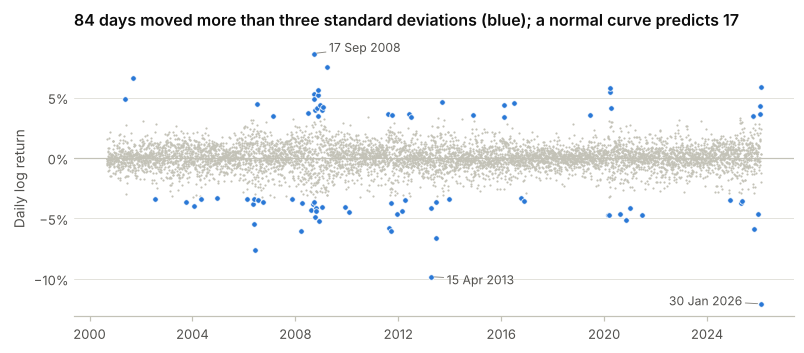

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 3.1), constrained_layout=True)
calm = z.abs() <= 3
ax.scatter(ret.index[calm], ret[calm], s=2, color=CONTEXT, linewidths=0, rasterized=True)
ax.scatter(ret.index[~calm], ret[~calm], s=13, color=BLUE, edgecolors="white", linewidths=0.5, zorder=3)
ax.axhline(0, color=AXIS, lw=0.8)
for day, text, off in [("2026-01-30", "30 Jan 2026", (-12, 2)), ("2013-04-15", "15 Apr 2013", (10, -2)),
                       ("2008-09-17", "17 Sep 2008", (10, 4))]:
    d = pd.Timestamp(day)
    note(ax, text, (d, ret[d]), off, ha="right" if off[0] < 0 else "left")
ax.set_ylabel("Daily log return")
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title(f"{int((~calm).sum())} days moved more than three standard deviations (blue); a normal curve predicts {2 * stats.norm.sf(3) * len(z):.0f}")
save(fig, "fig04_return_outliers")

**Price level.** The 1.5 x IQR rule puts the upper fence at $3,245 and flags 197 rows, all of them since
16 April 2025 (197 of the 205 trading days from that date to the end of the file). Those are not errors.
Gold did trade above $3,245. The IQR rule assumes the values come from one stable distribution, and a
price that has risen eighteen-fold in 25 years does not. An outlier test on the price level describes
the trend. It says nothing about data quality.

**Daily returns.** Here the rule makes sense, and it flags 317 days (5.0%). Measured in standard
deviations, 84 days moved more than three, against 17 expected under a normal distribution, and 13 moved
more than five, which a normal distribution would essentially never produce. The blue dots also come in
clusters (2006, 2008, 2011, 2013, 2020, 2025-26) instead of being spread evenly.

**Are the extreme days real?** We checked the largest moves against press reports from the time.

In [21]:
published = pd.DataFrame([
    {"date": "2008-09-17", "reported": "up $70 (9%), December contract settled at $850.50", "reported_change": 70.00,
     "source": "CNNMoney (2008)"},
    {"date": "2013-04-15", "reported": "down $140.30 (9%) to $1,361", "reported_change": -140.30,
     "source": "Associated Press (Rothwell, 2013)"},
    {"date": "2025-10-21", "reported": "front month down $248.70 (5.7%) to settle at $4,087.70", "reported_change": -248.70,
     "source": "InvestmentNews (Almazora, 2025)"},
]).set_index("date")
published.index = pd.to_datetime(published.index)
published["dataset_change"] = df.loc[published.index, "Price_Change"].round(2)
published["dataset_close"] = df.loc[published.index, "Close"].round(2)
published["dataset_change_%"] = df.loc[published.index, "Price_Change_Percent"].round(2)
published["difference_in_change"] = (published["dataset_change"] - published["reported_change"]).round(2)
display(published)
published.to_csv(RES_DIR / "external_check.csv")

,reported,reported_change,source,dataset_change,dataset_close,dataset_change_%,difference_in_change
date,,,,,,,
2008-09-17,"up $70 (9%), December contract settled at $850.50",70.0000,CNNMoney (2008),70.1000,846.6000,9.0300,0.1000
2013-04-15,"down $140.30 (9%) to $1,361",-140.3000,"Associated Press (Rothwell, 2013)",-140.4000,"1,360.6000",-9.3500,-0.1000
2025-10-21,front month down $248.70 (5.7%) to settle at $...,-248.7000,"InvestmentNews (Almazora, 2025)",-248.7000,"4,087.7000",-5.7400,0.0000


The dataset's daily change matches the reported figure to within 10 cents on all three days, and on
21 October 2025 the close is identical to the published front-month settlement ($4,087.70). The
extreme values are genuine market events.

**Decision.** We keep every row. Removing or capping the big days would delete exactly the days a gold
forecast is most useful for, and it would make the risk look smaller than it is. Instead we deal with
them in how we measure things:

* we work with log returns, which are less skewed than dollar changes;
* next to means, Pearson correlations and RMSE we report medians, Spearman correlations and MAE, which a
  single day cannot move much;
* in section 6 we check whether any model's score depends on one or two days. One does.

### 3.8 Feature engineering

The models may only use what was known at the close of day *t* to predict day *t + 1*. Every feature
below is calculated from prices up to and including day *t*. The targets are shifted one day forward.

We build 37 features in six families. Almost all come from `Close`, for the reasons in section 3.3.

In [22]:
def build_features(d):
    """Features known at the close of day t, built from the cleaned daily table."""
    c = d["Close"]
    r = d["log_return"]
    f = pd.DataFrame(index=d.index)

    # 1. Recent returns
    f["ret_1"] = r
    for k in range(1, 6):
        f[f"ret_lag{k}"] = r.shift(k)

    # 2. Momentum: cumulative log return over the last n days
    for n in (5, 10, 21, 63, 126, 252):
        f[f"mom_{n}"] = np.log(c / c.shift(n)) * 100

    # 3. Trend: distance of the price from the dataset's moving averages, and the averages from each other
    for n in (7, 30, 90, 365):
        f[f"dist_ma{n}"] = (c / d[f"MA_{n}"] - 1) * 100
    f["ma7_vs_ma30"] = (d["MA_7"] / d["MA_30"] - 1) * 100
    f["ma30_vs_ma90"] = (d["MA_30"] / d["MA_90"] - 1) * 100
    f["ma90_vs_ma365"] = (d["MA_90"] / d["MA_365"] - 1) * 100

    # 4. Volatility
    f["abs_ret_1"] = r.abs()
    f["vol_5"] = r.rolling(5).std()
    f["vol_10"] = r.rolling(10).std()
    f["vol_30"] = d["Volatility_30d"]                       # the dataset's own column
    f["vol_90"] = r.rolling(90).std()
    f["vol_5_over_30"] = f["vol_5"] / f["vol_30"]
    prev = c.shift(1)
    true_range = (np.maximum(d["High"], prev) - np.minimum(d["Low"], prev)) / prev * 100
    f["true_range"] = true_range                            # uses the repaired High and Low
    f["atr_14"] = true_range.rolling(14).mean()

    # 5. Oscillators
    delta = c.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    f["rsi_14"] = 100 - 100 / (1 + gain / loss)
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()
    f["bollinger_pos"] = (c - (mid - 2 * sd)) / (4 * sd)
    f["drawdown_252"] = (c / c.rolling(252).max() - 1) * 100

    # 6. Calendar (Monday is the reference day)
    for i, name in enumerate(["tue", "wed", "thu", "fri"], start=1):
        f[f"dow_{name}"] = (d.index.dayofweek == i).astype(int)
    f["month_sin"] = np.sin(2 * np.pi * d.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * d.index.month / 12)
    month_id = d.index.year * 12 + d.index.month
    f["first_day_of_month"] = np.r_[1, (month_id[1:] != month_id[:-1]).astype(int)]
    return f


FAMILIES = {
    "Recent returns": ["ret_1"] + [f"ret_lag{k}" for k in range(1, 6)],
    "Momentum": [f"mom_{n}" for n in (5, 10, 21, 63, 126, 252)],
    "Trend (moving averages)": ["dist_ma7", "dist_ma30", "dist_ma90", "dist_ma365", "ma7_vs_ma30", "ma30_vs_ma90", "ma90_vs_ma365"],
    "Volatility": ["abs_ret_1", "vol_5", "vol_10", "vol_30", "vol_90", "vol_5_over_30", "true_range", "atr_14"],
    "Oscillators": ["rsi_14", "bollinger_pos", "drawdown_252"],
    "Calendar": ["dow_tue", "dow_wed", "dow_thu", "dow_fri", "month_sin", "month_cos", "first_day_of_month"],
}

features = build_features(df)
FEATURES = list(features.columns)
assert sorted(FEATURES) == sorted(sum(FAMILIES.values(), []))

targets = pd.DataFrame({
    "y_ret": df["log_return"].shift(-1),                # tomorrow's log return (%)
    "next_close": df["Close"].shift(-1),                # tomorrow's close ($)
    "close": df["Close"],
})
targets["y_dir"] = (targets["y_ret"] > 0).astype(int)   # 1 if tomorrow closes higher
targets["y_abs"] = targets["y_ret"].abs()               # size of tomorrow's move (%)

model_df = features.join(targets).dropna()
print(f"Features: {len(FEATURES)}  |  modelling rows: {len(model_df):,}  "
      f"({model_df.index.min().date()} to {model_df.index.max().date()})")
print(f"Rows dropped: {len(df) - len(model_df)} "
      f"({len(df) - len(model_df) - 1} warm-up rows at the start, 1 row at the end with no 'tomorrow')")

RESULTS["features"] = {
    "n_features": len(FEATURES), "rows": int(len(model_df)),
    "first": str(model_df.index.min().date()), "last": str(model_df.index.max().date()),
    "dropped": int(len(df) - len(model_df)),
    "families": {k: len(v) for k, v in FAMILIES.items()},
}

Features: 37  |  modelling rows: 6,018  (2002-02-20 to 2026-02-05)
Rows dropped: 365 (364 warm-up rows at the start, 1 row at the end with no 'tomorrow')


In [23]:
display(model_df[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(3))

,mean,std,min,50%,max
ret_1,0.0470,1.1250,-12.0660,0.0580,8.6430
ret_lag1,0.0470,1.1250,-12.0660,0.0580,8.6430
ret_lag2,0.0460,1.1250,-12.0660,0.0580,8.6430
ret_lag3,0.0450,1.1220,-12.0660,0.0580,8.6430
ret_lag4,0.0460,1.1220,-12.0660,0.0580,8.6430
ret_lag5,0.0480,1.1110,-9.8210,0.0580,8.6430
mom_5,0.2310,2.4650,-14.4420,0.3370,18.5850
mom_10,0.4670,3.4090,-21.3540,0.4700,16.8900
mom_21,0.9790,4.8050,-23.3300,0.8790,20.6740
mom_63,2.8800,7.5960,-27.4970,2.9380,31.6140


**Leakage check.** If the features really stop at day *t*, changing the future must not change them. We
rebuild the features on a copy of the data in which everything after one cut-off date is scrambled, and
compare the rows up to the cut-off.

In [24]:
cut = pd.Timestamp("2015-06-30")
tampered = df.copy()
after = tampered.index > cut
for col in ["Open", "High", "Low", "Close", "MA_7", "MA_30", "MA_90", "MA_365", "Volatility_30d", "log_return"]:
    tampered.loc[after, col] = rng.permutation(tampered.loc[after, col].to_numpy())
same = np.allclose(build_features(tampered).loc[:cut].to_numpy(), features.loc[:cut].to_numpy(), equal_nan=True)
print("Features up to the cut-off are unchanged when the future is scrambled:", same)
RESULTS["features"]["leakage_test_passed"] = bool(same)

Features up to the cut-off are unchanged when the future is scrambled: True


## 4. Exploratory data analysis

### 4.1 The price over 25 years

In [25]:
close = df["Close"]
milestones = {lvl: close[close >= lvl].index.min() for lvl in (1000, 2000, 3000, 4000, 5000)}
peak_2011 = close[:"2012"].idxmax()
trough_2015 = close["2011-09":"2016"].idxmin()
ath = close.idxmax()
years_elapsed = (close.index[-1] - close.index[0]).days / 365.25
cagr = (close.iloc[-1] / close.iloc[0]) ** (1 / years_elapsed) - 1
print(f"First close ${close.iloc[0]:,.2f} | last close ${close.iloc[-1]:,.2f} | multiple {close.iloc[-1] / close.iloc[0]:.1f}x | "
      f"compound annual growth {cagr:.1%}")
print("First close at or above:", {f"${k:,}": v.date().isoformat() for k, v in milestones.items()})
print(f"2011 peak ${close[peak_2011]:,.1f} on {peak_2011.date()} | trough ${close[trough_2015]:,.1f} on {trough_2015.date()} | "
      f"record close ${close[ath]:,.1f} on {ath.date()}")

RESULTS["price"] = {
    "first_close": float(close.iloc[0]), "last_close": float(close.iloc[-1]),
    "multiple": float(close.iloc[-1] / close.iloc[0]), "cagr_pct": float(cagr * 100),
    "milestones": {str(k): v.date().isoformat() for k, v in milestones.items()},
    "peak_2011": [peak_2011.date().isoformat(), float(close[peak_2011])],
    "trough_2015": [trough_2015.date().isoformat(), float(close[trough_2015])],
    "ath": [ath.date().isoformat(), float(close[ath])],
    "min_close": float(close.min()), "min_close_date": close.idxmin().date().isoformat(),
}

First close $273.90 | last close $4,979.80 | multiple 18.2x | compound annual growth 12.1%
First close at or above: {'$1,000': '2008-03-17', '$2,000': '2020-08-04', '$3,000': '2025-03-17', '$4,000': '2025-10-08', '$5,000': '2026-01-26'}
2011 peak $1,888.7 on 2011-08-22 | trough $1,050.8 on 2015-12-17 | record close $5,318.4 on 2026-01-29


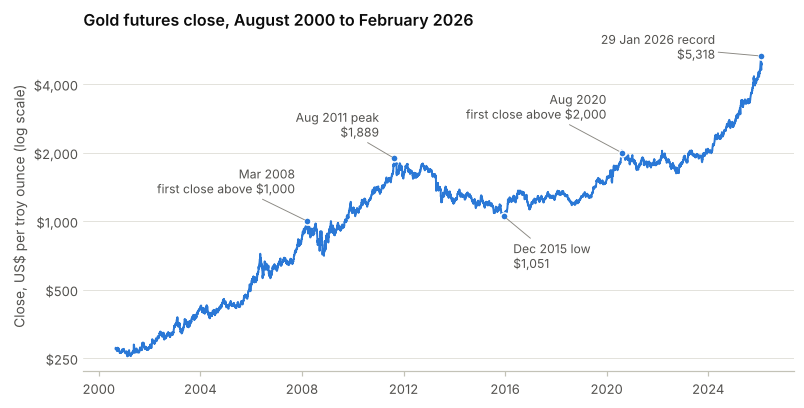

In [26]:
fig, ax = plt.subplots(figsize=(7.2, 3.6), constrained_layout=True)
ax.plot(close.index, close, color=BLUE, lw=1.3)
ax.set_yscale("log")
ax.set_yticks([250, 500, 1000, 2000, 4000])
ax.yaxis.set_major_formatter(dollars)
ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_ylabel("Close, US$ per troy ounce (log scale)")
marks = [
    (milestones[1000], "Mar 2008\nfirst close above $1,000", (-8, 26), "right"),
    (peak_2011, f"Aug 2011 peak\n${close[peak_2011]:,.0f}", (-10, 22), "right"),
    (trough_2015, f"Dec 2015 low\n${close[trough_2015]:,.0f}", (6, -26), "left"),
    (milestones[2000], "Aug 2020\nfirst close above $2,000", (-10, 30), "right"),
    (ath, f"29 Jan 2026 record\n${close[ath]:,.0f}", (-30, 6), "right"),
]
for day, text, off, ha in marks:
    ax.scatter([day], [close[day]], s=22, color=BLUE, edgecolors="white", linewidths=1, zorder=3)
    note(ax, text, (day, close[day]), off, ha=ha)
ax.set_title("Gold futures close, August 2000 to February 2026")
save(fig, "fig05_price_history")

Gold went from $274 to $4,980, an 18-fold rise or about 12% a year compounded. The log scale shows that
the climb came in three legs with a long setback between the first two: a steady run from 2001 to the
August 2011 peak of $1,889, a slide to $1,051 by December 2015, and a recovery that turned into a surge
from 2024. The price took almost nine years to get back above its 2011 peak. It then needed ten months
to go from $3,000 (March 2025) to $5,000 (January 2026).

### 4.2 Descriptive statistics

In [27]:
def describe(s):
    s = s.dropna()
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "std": s.std(), "min": s.min(),
                      "max": s.max(), "skewness": stats.skew(s), "excess_kurtosis": stats.kurtosis(s)})


summary = pd.DataFrame({
    "Close (US$)": describe(df["Close"]),
    "Daily log return (%)": describe(df["log_return"]),
    "Absolute daily return (%)": describe(df["log_return"].abs()),
    "Volatility_30d (%)": describe(df["Volatility_30d"]),
    "Volume (contracts)": describe(df["Volume"]),
}).T
display(summary.round(3))
summary.to_csv(RES_DIR / "descriptive_statistics.csv")

up_share = (ret > 0).mean()
print(f"Up days {up_share:.1%} | flat days {(ret == 0).mean():.1%} | annualised mean return {ret.mean() * 252:.1f}% | "
      f"annualised volatility {ret.std() * np.sqrt(252):.1f}%")
RESULTS["returns"] = {
    "n": int(len(ret)), "mean": float(ret.mean()), "median": float(ret.median()), "std": float(ret.std()),
    "skew": float(stats.skew(ret)), "excess_kurtosis": float(stats.kurtosis(ret)),
    "min": float(ret.min()), "max": float(ret.max()), "up_share_pct": float(up_share * 100),
    "ann_return_pct": float(ret.mean() * 252), "ann_vol_pct": float(ret.std() * np.sqrt(252)),
    "mean_abs": float(ret.abs().mean()), "median_abs": float(ret.abs().median()),
}

,n,mean,median,std,min,max,skewness,excess_kurtosis
Close (US$),"6,383.0000","1,265.3740","1,250.2000",760.2680,255.1000,"5,318.4000",1.2710,3.1110
Daily log return (%),"6,382.0000",0.0450,0.0520,1.1120,-12.0660,8.6430,-0.4670,7.0810
Absolute daily return (%),"6,382.0000",0.7820,0.5540,0.7930,0.0000,12.0660,2.8700,17.7450
Volatility_30d (%),"6,353.0000",1.0270,0.9320,0.4020,0.4320,3.2140,1.8450,4.4620
Volume (contracts),"6,383.0000","4,315.0270",117.0000,"24,170.7800",0.0000,"386,334.0000",7.8100,69.1570


Up days 52.8% | flat days 0.7% | annualised mean return 11.5% | annualised volatility 17.7%


Date,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
year_end_close,272.0000,278.7000,347.6000,415.7000,437.5000,517.1000,635.2000,834.9000,883.6000,"1,095.2000","1,421.1000","1,565.8000","1,674.8000","1,201.9000","1,183.9000","1,060.3000","1,150.0000","1,306.3000","1,278.3000","1,519.5000","1,893.1000","1,827.5000","1,819.7000","2,062.4000","2,629.2000","4,325.6000","4,979.8000"
return_%,NaN,2.5000,24.7000,19.6000,5.2000,18.2000,22.8000,31.4000,5.8000,23.9000,29.8000,10.2000,7.0000,-28.2000,-1.5000,-10.4000,8.5000,13.6000,-2.1000,18.9000,24.6000,-3.5000,-0.4000,13.3000,27.5000,64.5000,15.1000
annualised_volatility_%,10.5000,14.8000,13.6000,16.8000,16.4000,12.6000,24.0000,16.6000,30.5000,22.1000,16.0000,21.2000,16.3000,22.5000,14.2000,14.7000,16.2000,10.4000,10.5000,11.5000,21.4000,15.0000,15.5000,13.2000,15.0000,20.5000,50.6000
up_days_%,39.8000,49.0000,54.4000,55.2000,52.2000,54.0000,51.6000,54.0000,50.6000,56.0000,59.9000,56.7000,52.0000,45.6000,47.2000,44.4000,48.8000,55.0000,48.0000,54.4000,58.5000,53.6000,52.6000,50.8000,57.5000,59.9000,68.0000
trading_days,84.0000,247.0000,250.0000,250.0000,249.0000,248.0000,250.0000,252.0000,253.0000,252.0000,252.0000,252.0000,250.0000,252.0000,252.0000,252.0000,250.0000,251.0000,250.0000,252.0000,253.0000,252.0000,251.0000,250.0000,252.0000,252.0000,25.0000


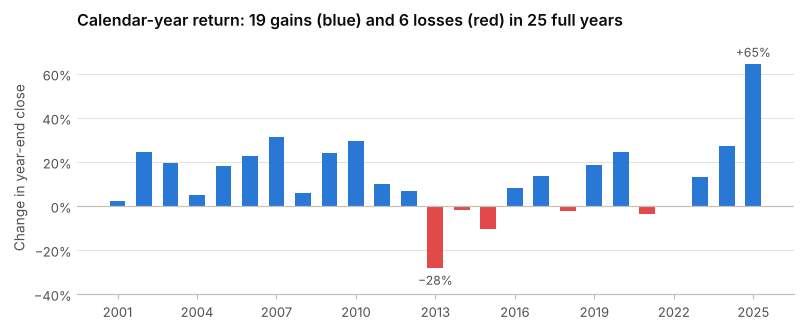

In [28]:
year_end = close.groupby(close.index.year).last()
annual = pd.DataFrame({
    "year_end_close": year_end,
    "return_%": year_end.pct_change(fill_method=None) * 100,
    "annualised_volatility_%": ret.groupby(ret.index.year).std() * np.sqrt(252),
    "up_days_%": (ret > 0).groupby(ret.index.year).mean() * 100,
    "trading_days": close.groupby(close.index.year).size(),
})
display(annual.round(1).T)
annual.to_csv(RES_DIR / "annual_summary.csv")

full_years = annual.loc[2001:2025, "return_%"]
RESULTS["annual"] = {
    "up_years": int((full_years > 0).sum()), "n_years": int(len(full_years)),
    "best": [int(full_years.idxmax()), float(full_years.max())],
    "worst": [int(full_years.idxmin()), float(full_years.min())],
    "median_return": float(full_years.median()),
    "ytd_2026": float(annual.loc[2026, "return_%"]),
    "vol_2026": float(annual.loc[2026, "annualised_volatility_%"]),
    "vol_2008": float(annual.loc[2008, "annualised_volatility_%"]),
    "calmest_year": [int(annual.loc[2001:2025, "annualised_volatility_%"].idxmin()),
                     float(annual.loc[2001:2025, "annualised_volatility_%"].min())],
}

fig, ax = plt.subplots(figsize=(7.2, 2.9), constrained_layout=True)
ax.bar(full_years.index, full_years, width=0.6, color=[BLUE if v >= 0 else RED for v in full_years])
ax.axhline(0, color=AXIS, lw=0.8)
for y in (full_years.idxmax(), full_years.idxmin()):
    v = full_years[y]
    ax.text(y, v + (2 if v > 0 else -2), f"{v:+.0f}%".replace("-", "\u2212"), ha="center", va="bottom" if v > 0 else "top", fontsize=8, color=INK_2)
ax.set_ylim(-40, 75)
ax.set_xticks(range(2001, 2026, 3))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Change in year-end close")
ax.set_title(f"Calendar-year return: {int((full_years > 0).sum())} gains (blue) and {int((full_years < 0).sum())} losses (red) in 25 full years")
save(fig, "fig06_annual_returns")

The average day is almost nothing: +0.05%, with 52.8% of days up. The typical move is much bigger than
the average one. The standard deviation is 1.11%, and half of all days move more than 0.55% in one
direction or the other. A mean that is one twenty-fifth of the standard deviation is the reason daily
prediction is hard: the drift that made gold rise 18-fold is invisible at the scale of one day.

Year by year, gold rose in 19 of 25 full calendar years. 2025 was the best (+65%) and 2013 the worst (-28%).

### 4.3 The distribution of daily returns

Skewness -0.467 | excess kurtosis 7.08
Jarque-Bera 13,567 (p = 0) | D'Agostino K2 1,117 (p = 2.92e-243) | Kolmogorov-Smirnov D = 0.074 (p = 9.19e-31)


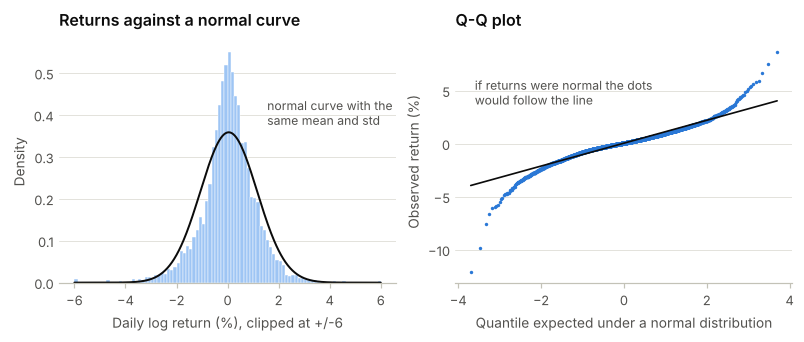

In [29]:
jb = stats.jarque_bera(ret)
dag = stats.normaltest(ret)
ks = stats.kstest((ret - ret.mean()) / ret.std(), "norm")
print(f"Skewness {stats.skew(ret):.3f} | excess kurtosis {stats.kurtosis(ret):.2f}")
print(f"Jarque-Bera {jb.statistic:,.0f} (p = {jb.pvalue:.3g}) | D'Agostino K2 {dag.statistic:,.0f} (p = {dag.pvalue:.3g}) | "
      f"Kolmogorov-Smirnov D = {ks.statistic:.3f} (p = {ks.pvalue:.3g})")
RESULTS["normality"] = {"jb": float(jb.statistic), "jb_p": float(jb.pvalue), "dagostino": float(dag.statistic),
                        "dagostino_p": float(dag.pvalue), "ks": float(ks.statistic), "ks_p": float(ks.pvalue)}

fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
bins = np.linspace(-6, 6, 97)
a.hist(ret.clip(-6, 6), bins=bins, density=True, color=BLUE_LIGHT, edgecolor="white", linewidth=0.3)
xs = np.linspace(-6, 6, 400)
a.plot(xs, stats.norm.pdf(xs, ret.mean(), ret.std()), color=INK, lw=1.3)
a.set_xlabel("Daily log return (%), clipped at +/-6")
a.set_ylabel("Density")
a.set_title("Returns against a normal curve")
a.text(1.55, 0.44, "normal curve with the\nsame mean and std", fontsize=8, color=INK_2, va="top")
(osm, osr), (slope, intercept, _) = stats.probplot(ret, dist="norm")
b.scatter(osm, osr, s=5, color=BLUE, linewidths=0, rasterized=True)
b.plot(osm, slope * osm + intercept, color=INK, lw=1.1)
b.set_xlabel("Quantile expected under a normal distribution")
b.set_ylabel("Observed return (%)")
b.set_title("Q-Q plot")
b.text(-3.6, 6.2, "if returns were normal the dots\nwould follow the line", fontsize=8, color=INK_2, va="top")
save(fig, "fig07_return_distribution")

Returns are not normally distributed, and all three tests reject normality with p-values that round to
zero. Compared with a bell curve the histogram has a taller, narrower centre and longer tails (excess
kurtosis 7.1), and the left tail is the longer one (skewness -0.47). In the Q-Q plot both ends bend away
from the line: large moves are far more frequent than a normal model allows.

### 4.4 Volatility comes in clusters

{'count': 6353.0, 'mean': 1.027, 'std': 0.402, 'min': 0.432, '25%': 0.764, '50%': 0.932, '75%': 1.164, 'max': 3.214}
{'2008': ('2008-10-23', 3.21), '2013': ('2013-05-23', 2.25), '2020': ('2020-04-09', 2.65), '2026': ('2026-02-06', 2.99)}


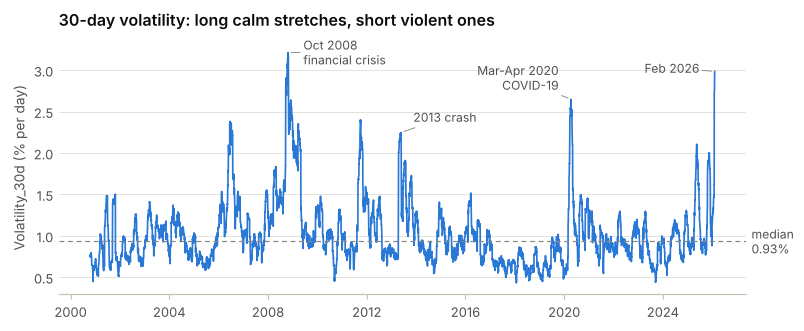

In [30]:
vol30 = df["Volatility_30d"]
print(vol30.describe().round(3).to_dict())
vol_peaks = {"2008": vol30["2008"].idxmax(), "2013": vol30["2013"].idxmax(), "2020": vol30["2020"].idxmax(), "2026": vol30["2026"].idxmax()}
print({k: (v.date().isoformat(), round(float(vol30[v]), 2)) for k, v in vol_peaks.items()})
RESULTS["volatility"] = {
    "median": float(vol30.median()), "min": float(vol30.min()), "max": float(vol30.max()),
    "max_date": vol30.idxmax().date().isoformat(),
    "peaks": {k: [v.date().isoformat(), float(vol30[v])] for k, v in vol_peaks.items()},
    "q25": float(vol30.quantile(0.25)), "q75": float(vol30.quantile(0.75)),
}

fig, ax = plt.subplots(figsize=(7.2, 2.9), constrained_layout=True)
ax.plot(vol30.index, vol30, color=BLUE, lw=1.1)
ax.axhline(vol30.median(), color=MUTED, lw=0.8, ls=(0, (4, 3)))
ax.text(1.008, vol30.median(), f"median\n{vol30.median():.2f}%", transform=ax.get_yaxis_transform(), fontsize=8, color=INK_2, va="center")
labels = {"2008": "Oct 2008\nfinancial crisis", "2013": "2013 crash", "2020": "Mar-Apr 2020\nCOVID-19", "2026": "Feb 2026"}
offsets = {"2008": (10, 0), "2013": (8, 10), "2020": (-8, 14), "2026": (-10, 2)}
for k, day in vol_peaks.items():
    note(ax, labels[k], (day, vol30[day]), offsets[k], ha="left" if offsets[k][0] > 0 else "right")
ax.set_ylabel("Volatility_30d (% per day)")
ax.set_title("30-day volatility: long calm stretches, short violent ones")
save(fig, "fig08_volatility_over_time")

95% band +/-0.0245
ACF of returns, lags 1-5: [-0.0134 -0.0195  0.0149 -0.008   0.006 ] | lags outside the band: 4 of 40
ACF of |returns|, lags 1-5: [0.097  0.156  0.1242 0.1319 0.1392] | lag 20: 0.1186 | lag 40: 0.0699
Ljung-Box, returns: Q(10) = 19.5 (p = 0.035), Q(20) = 33.5 (p = 0.030)
Ljung-Box, |returns|: Q(10) = 1,092 (p = 3e-228)
ARCH-LM (10 lags): 329.4 (p = 9.12e-65)


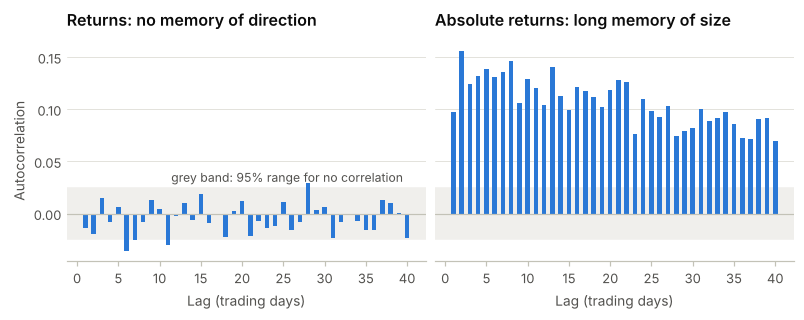

In [31]:
n_lags = 40
acf_ret = acf(ret, nlags=n_lags, fft=True)[1:]
acf_abs = acf(ret.abs(), nlags=n_lags, fft=True)[1:]
band = 1.96 / np.sqrt(len(ret))
lb_ret = acorr_ljungbox(ret, lags=[10, 20])
lb_abs = acorr_ljungbox(ret.abs(), lags=[10, 20])
arch_lm, arch_p = het_arch(ret - ret.mean(), nlags=10)[:2]
print(f"95% band +/-{band:.4f}")
print("ACF of returns, lags 1-5:", acf_ret[:5].round(4), "| lags outside the band:", int((np.abs(acf_ret) > band).sum()), "of", n_lags)
print("ACF of |returns|, lags 1-5:", acf_abs[:5].round(4), "| lag 20:", acf_abs[19].round(4), "| lag 40:", acf_abs[39].round(4))
print(f"Ljung-Box, returns: Q(10) = {lb_ret['lb_stat'].iloc[0]:.1f} (p = {lb_ret['lb_pvalue'].iloc[0]:.3f}), "
      f"Q(20) = {lb_ret['lb_stat'].iloc[1]:.1f} (p = {lb_ret['lb_pvalue'].iloc[1]:.3f})")
print(f"Ljung-Box, |returns|: Q(10) = {lb_abs['lb_stat'].iloc[0]:,.0f} (p = {lb_abs['lb_pvalue'].iloc[0]:.3g})")
print(f"ARCH-LM (10 lags): {arch_lm:.1f} (p = {arch_p:.3g})")
RESULTS["autocorrelation"] = {
    "band": float(band), "acf_ret_lag1": float(acf_ret[0]), "acf_ret_max_abs": float(np.abs(acf_ret).max()),
    "acf_ret_outside": int((np.abs(acf_ret) > band).sum()), "n_lags": n_lags,
    "acf_abs_lag1": float(acf_abs[0]), "acf_abs_lag2": float(acf_abs[1]), "acf_abs_lag20": float(acf_abs[19]), "acf_abs_lag40": float(acf_abs[39]),
    "acf_abs_min": float(acf_abs.min()),
    "lb_ret_q10": float(lb_ret["lb_stat"].iloc[0]), "lb_ret_p10": float(lb_ret["lb_pvalue"].iloc[0]),
    "lb_ret_q20": float(lb_ret["lb_stat"].iloc[1]), "lb_ret_p20": float(lb_ret["lb_pvalue"].iloc[1]),
    "lb_abs_q10": float(lb_abs["lb_stat"].iloc[0]), "lb_abs_p10": float(lb_abs["lb_pvalue"].iloc[0]),
    "arch_lm": float(arch_lm), "arch_p": float(arch_p),
    "close_lag1_corr": float(close.autocorr(1)), "ret_lag1_corr": float(ret.autocorr(1)),
}

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), sharey=True, constrained_layout=True)
for ax, values, title in [(axes[0], acf_ret, "Returns: no memory of direction"),
                          (axes[1], acf_abs, "Absolute returns: long memory of size")]:
    ax.axhspan(-band, band, color=NEUTRAL, zorder=0)
    ax.bar(range(1, n_lags + 1), values, width=0.55, color=BLUE)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xlabel("Lag (trading days)")
    ax.set_title(title)
axes[0].set_ylabel("Autocorrelation")
axes[0].text(39.5, band + 0.006, "grey band: 95% range for no correlation", fontsize=8, color=INK_2, ha="right")
save(fig, "fig09_autocorrelation")

`Volatility_30d` spends most of its time between 0.76% and 1.16% a day and then spikes: 3.2% in October
2008, and close to 3% again in February 2026.

The autocorrelation plots explain what a model can and cannot hope to learn from past prices:

* **Direction has almost no memory.** The correlation between today's return and yesterday's is -0.013.
  Four of 40 lags sit just outside the grey band and the largest is 0.035 in size. With 6,382 days the
  Ljung-Box test can detect that (p = 0.035 at ten lags), but a correlation of 0.035 explains about a
  tenth of one percent of the variance.
* **Size has a long memory.** The absolute return is correlated with its own past at every one of the 40
  lags. A big move today makes a big move tomorrow more likely, in either direction, and the effect is
  still visible two months later. The ARCH-LM test confirms it (p < 0.001).

### 4.5 Stationarity

In [32]:
def unit_root_tests(s, name):
    a = adfuller(s.dropna(), autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        k = kpss(s.dropna(), regression="c", nlags="auto")
    return {"series": name, "ADF_statistic": a[0], "ADF_p": a[1], "KPSS_statistic": k[0], "KPSS_p": k[1],
            "verdict": "stationary" if (a[1] < 0.05 and k[1] > 0.05) else "not stationary"}


stationarity = pd.DataFrame([
    unit_root_tests(df["Close"], "Close"),
    unit_root_tests(np.log(df["Close"]), "log(Close)"),
    unit_root_tests(df["log_return"], "Daily log return"),
]).set_index("series")
display(stationarity.round(4))
stationarity.to_csv(RES_DIR / "stationarity_tests.csv")
RESULTS["stationarity"] = {k: {c: (float(v) if not isinstance(v, str) else v) for c, v in row.items()}
                           for k, row in stationarity.to_dict("index").items()}

,ADF_statistic,ADF_p,KPSS_statistic,KPSS_p,verdict
series,,,,,
Close,5.2976,1.0000,9.0840,0.0100,not stationary
log(Close),0.0253,0.9606,10.2676,0.0100,not stationary
Daily log return,-25.4512,0.0000,0.1949,0.1000,stationary


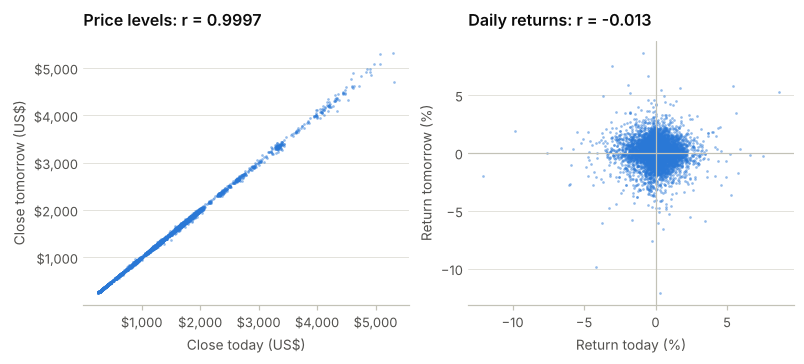

In [33]:
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.2), constrained_layout=True)
a.scatter(close[:-1], close[1:], s=3, color=BLUE, linewidths=0, alpha=0.5, rasterized=True)
a.set_xlabel("Close today (US$)")
a.set_ylabel("Close tomorrow (US$)")
a.xaxis.set_major_formatter(dollars)
a.yaxis.set_major_formatter(dollars)
a.set_title(f"Price levels: r = {close.autocorr(1):.4f}")
b.scatter(ret[:-1], ret[1:], s=3, color=BLUE, linewidths=0, alpha=0.5, rasterized=True)
b.axhline(0, color=AXIS, lw=0.8)
b.axvline(0, color=AXIS, lw=0.8)
b.set_xlabel("Return today (%)")
b.set_ylabel("Return tomorrow (%)")
b.set_title(f"Daily returns: r = {ret.autocorr(1):.3f}")
save(fig, "fig10_lag_scatter")

The price level is not stationary: the ADF test cannot reject a unit root (p = 1.00) and the KPSS test
rejects stationarity. Daily log returns pass both tests. So the level wanders without a fixed mean, and
the returns have one.

The two scatter plots are the same data seen two ways, and they are the most important picture in the
project. On the left, tomorrow's price is almost perfectly predicted by today's price (r = 0.9997). On
the right, tomorrow's *change* is not predicted by today's change at all (r = -0.013). A model scored on
the left-hand picture will look brilliant while knowing nothing.

### 4.6 Seasonality: weekdays and months

In [34]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
by_day = ret.groupby(ret.index.day_name())
weekday = pd.DataFrame({"n": by_day.size(), "mean_%": by_day.mean(), "median_%": by_day.median(), "std_%": by_day.std(),
                        "up_days_%": by_day.apply(lambda s: (s > 0).mean() * 100)}).loc[day_order]
weekday["ci95"] = 1.96 * weekday["std_%"] / np.sqrt(weekday["n"])
display(weekday.round(3))

groups_day = [ret[ret.index.day_name() == d] for d in day_order]
kw_day = stats.kruskal(*groups_day)
anova_day = stats.f_oneway(*groups_day)
levene_day = stats.levene(*groups_day)
ct_day = pd.crosstab(ret.index.day_name(), ret > 0).loc[day_order]
chi_day = stats.chi2_contingency(ct_day)
cramers_v_day = np.sqrt(chi_day[0] / (ct_day.to_numpy().sum() * (min(ct_day.shape) - 1)))
print(f"Weekday, mean return: Kruskal-Wallis H = {kw_day.statistic:.2f} (p = {kw_day.pvalue:.3f}); ANOVA F = {anova_day.statistic:.2f} (p = {anova_day.pvalue:.3f})")
print(f"Weekday, spread: Levene W = {levene_day.statistic:.2f} (p = {levene_day.pvalue:.4f})")
print(f"Weekday vs up/down: chi-square = {chi_day[0]:.2f} (p = {chi_day[1]:.3f}), Cramer's V = {cramers_v_day:.3f}")

month_end = close.groupby([close.index.year, close.index.month]).last()
monthly_ret = (month_end.pct_change(fill_method=None) * 100).dropna()
monthly_ret.index.names = ["year", "month"]
monthly_ret = monthly_ret.iloc[:-1]            # February 2026 has only five trading days in the file
by_month = monthly_ret.groupby("month")
month_table = pd.DataFrame({"n": by_month.size(), "mean_%": by_month.mean(), "median_%": by_month.median(),
                            "std_%": by_month.std(), "positive_%": by_month.apply(lambda s: (s > 0).mean() * 100)})
month_table["ci95"] = 1.96 * month_table["std_%"] / np.sqrt(month_table["n"])
month_table.index = month_names
display(month_table.round(2))
kw_month = stats.kruskal(*[monthly_ret.xs(m, level="month") for m in range(1, 13)])
kw_month_daily = stats.kruskal(*[ret[ret.index.month == m] for m in range(1, 13)])
ct_month = pd.crosstab(ret.index.month, ret > 0)
chi_month = stats.chi2_contingency(ct_month)
cramers_v_month = np.sqrt(chi_month[0] / (ct_month.to_numpy().sum() * (min(ct_month.shape) - 1)))
print(f"Month, monthly returns: Kruskal-Wallis H = {kw_month.statistic:.2f} (p = {kw_month.pvalue:.3f})")
print(f"Month, daily returns: Kruskal-Wallis H = {kw_month_daily.statistic:.2f} (p = {kw_month_daily.pvalue:.3f})")
print(f"Month vs up/down: chi-square = {chi_month[0]:.2f} (p = {chi_month[1]:.3f}), Cramer's V = {cramers_v_month:.3f}")

first_day = features["first_day_of_month"].reindex(ret.index) == 1
t_first = stats.ttest_ind(ret[first_day], ret[~first_day], equal_var=False)
print(f"First trading day of the month: mean {ret[first_day].mean():.3f}% (n = {int(first_day.sum())}) vs {ret[~first_day].mean():.3f}% on other days; "
      f"Welch t = {t_first.statistic:.2f}, p = {t_first.pvalue:.3f}")

weekday.to_csv(RES_DIR / "weekday_returns.csv")
month_table.to_csv(RES_DIR / "month_returns.csv")
RESULTS["seasonality"] = {
    "weekday": {d: {"mean": float(weekday.loc[d, "mean_%"]), "up": float(weekday.loc[d, "up_days_%"]), "std": float(weekday.loc[d, "std_%"])} for d in day_order},
    "kw_day": float(kw_day.statistic), "kw_day_p": float(kw_day.pvalue),
    "anova_day": float(anova_day.statistic), "anova_day_p": float(anova_day.pvalue),
    "kw_month_daily": float(kw_month_daily.statistic), "kw_month_daily_p": float(kw_month_daily.pvalue),
    "levene_day": float(levene_day.statistic), "levene_day_p": float(levene_day.pvalue),
    "chi_day": float(chi_day[0]), "chi_day_p": float(chi_day[1]), "cramers_v_day": float(cramers_v_day),
    "month": {m: {"mean": float(month_table.loc[m, "mean_%"]), "positive": float(month_table.loc[m, "positive_%"]), "n": int(month_table.loc[m, "n"])} for m in month_names},
    "kw_month": float(kw_month.statistic), "kw_month_p": float(kw_month.pvalue),
    "chi_month": float(chi_month[0]), "chi_month_p": float(chi_month[1]), "cramers_v_month": float(cramers_v_month),
    "first_day_mean": float(ret[first_day].mean()), "other_day_mean": float(ret[~first_day].mean()),
    "first_day_t": float(t_first.statistic), "first_day_p": float(t_first.pvalue), "first_day_n": int(first_day.sum()),
    "monthly_mean": float(monthly_ret.mean()), "monthly_std": float(monthly_ret.std()),
    "monthly_best": [int(monthly_ret.idxmax()[0]), int(monthly_ret.idxmax()[1]), float(monthly_ret.max())],
    "monthly_worst": [int(monthly_ret.idxmin()[0]), int(monthly_ret.idxmin()[1]), float(monthly_ret.min())],
    "monthly_positive_pct": float((monthly_ret > 0).mean() * 100),
}

,n,mean_%,median_%,std_%,up_days_%,ci95
Date,,,,,,
Monday,1195,0.0540,0.0520,1.0940,53.3050,0.0620
Tuesday,1314,0.0150,0.0320,1.0680,51.5220,0.0580
Wednesday,1310,0.0350,0.0500,1.0540,52.6720,0.0570
Thursday,1287,0.0430,0.0310,1.1650,51.1270,0.0640
Friday,1276,0.0830,0.0920,1.1760,55.3290,0.0650


Weekday, mean return: Kruskal-Wallis H = 4.57 (p = 0.335); ANOVA F = 0.65 (p = 0.630)
Weekday, spread: Levene W = 4.53 (p = 0.0012)
Weekday vs up/down: chi-square = 5.71 (p = 0.222), Cramer's V = 0.030


,n,mean_%,median_%,std_%,positive_%,ci95
Jan,26,3.0000,3.2100,4.8200,65.3800,1.8500
Feb,25,0.8000,0.4500,4.3900,52.0000,1.7200
Mar,25,0.7300,-0.4200,4.0900,48.0000,1.6000
Apr,25,1.2900,1.4700,4.7600,64.0000,1.8700
May,25,0.3400,0.4700,4.2700,52.0000,1.6700
Jun,25,-0.4700,-1.5000,4.8400,44.0000,1.9000
Jul,25,0.9800,1.1600,3.9200,56.0000,1.5400
Aug,25,2.0200,2.7700,4.3000,72.0000,1.6900
Sep,26,0.7600,-0.1200,5.5600,50.0000,2.1400
Oct,26,0.2100,0.3500,4.9400,50.0000,1.9000


Month, monthly returns: Kruskal-Wallis H = 10.39 (p = 0.496)
Month, daily returns: Kruskal-Wallis H = 10.62 (p = 0.476)
Month vs up/down: chi-square = 7.73 (p = 0.737), Cramer's V = 0.035
First trading day of the month: mean 0.166% (n = 306) vs 0.039% on other days; Welch t = 1.84, p = 0.066


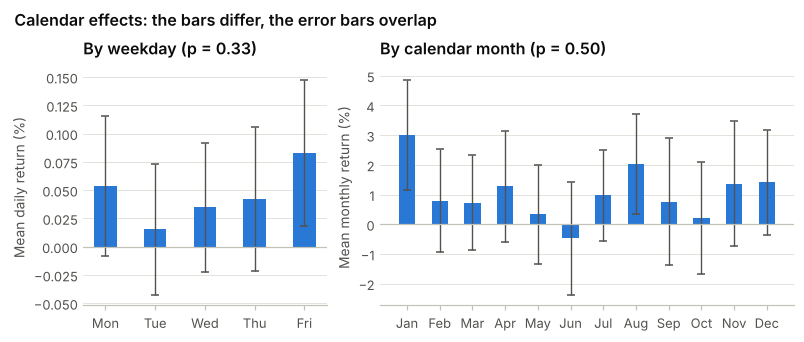

In [35]:
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.7]})
a.bar([d[:3] for d in day_order], weekday["mean_%"], width=0.45, color=BLUE)
a.errorbar([d[:3] for d in day_order], weekday["mean_%"], yerr=weekday["ci95"], fmt="none", ecolor=INK_2, elinewidth=0.9, capsize=2.5)
a.axhline(0, color=AXIS, lw=0.8)
a.set_ylabel("Mean daily return (%)")
a.set_title(f"By weekday (p = {kw_day.pvalue:.2f})")
b.bar(month_names, month_table["mean_%"], width=0.5, color=BLUE)
b.errorbar(month_names, month_table["mean_%"], yerr=month_table["ci95"], fmt="none", ecolor=INK_2, elinewidth=0.9, capsize=2.5)
b.axhline(0, color=AXIS, lw=0.8)
b.set_ylabel("Mean monthly return (%)")
b.set_title(f"By calendar month (p = {kw_month.pvalue:.2f})")
fig.suptitle("Calendar effects: the bars differ, the error bars overlap", x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
save(fig, "fig11_seasonality")

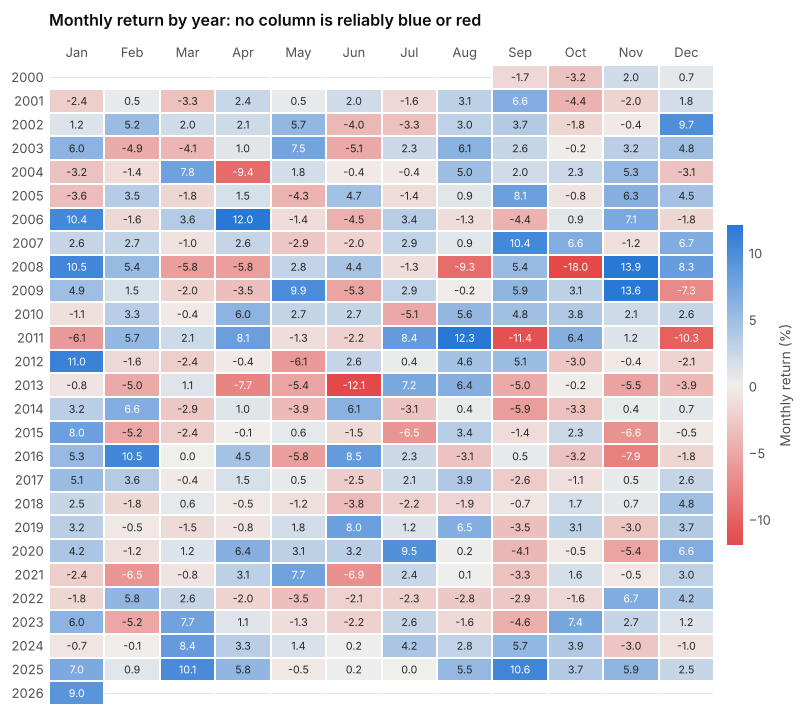

In [36]:
heat = monthly_ret.unstack("month").round(1) + 0.0     # "+ 0.0" turns -0.0 into 0.0
heat.columns = month_names
fig, ax = plt.subplots(figsize=(7.2, 6.4), constrained_layout=True)
lim = 12
sns.heatmap(heat, cmap=DIVERGING, center=0, vmin=-lim, vmax=lim, annot=True, fmt=".1f", annot_kws={"size": 7},
            linewidths=1.2, linecolor="white", cbar_kws={"shrink": 0.5, "label": "Monthly return (%)", "pad": 0.02}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.tick_top()
ax.tick_params(axis="both", length=0)
ax.set_title("Monthly return by year: no column is reliably blue or red", pad=26)
save(fig, "fig12_monthly_heatmap")

Friday has the highest average return and Tuesday the lowest, January and August look strong and June
weak. None of it survives a test. The Kruskal-Wallis p-values are 0.33 for weekdays and about 0.5 for
months, and the association between weekday and up/down is negligible (Cramer's V = 0.03). In the
heatmap every month has both blue and red years.

One calendar effect is significant, and it concerns risk: the *spread* of returns differs by weekday
(Levene p = 0.001), with Thursdays and Fridays more volatile than the first three days of the week.

The first trading day of a month averages +0.17% against +0.04% on other days. That falls short of
the 5% level (Welch p = 0.066), and we would not trust it even if it passed: we ran eight calendar
tests, and a front-month series can jump when it switches to a later, more expensive contract.

### 4.7 Drawdowns

,peak_date,peak_price,trough_date,trough_price,depth_%,recovered_on,days_peak_to_recovery
116,2011-08-22,"1,888.7000",2015-12-17,"1,050.8000",-44.4000,2020-07-23,"3,258.0000"
83,2008-03-18,"1,003.2000",2008-11-13,704.9000,-29.7000,2009-09-11,542.0000
67,2006-05-11,719.8000,2006-10-04,562.0000,-21.9000,2007-09-19,496.0000
118,2020-08-06,"2,051.5000",2022-09-26,"1,623.3000",-20.9000,2023-12-01,"1,212.0000"
21,2003-02-04,379.0000,2003-04-07,321.5000,-15.2000,2003-09-09,217.0000
90,2009-12-03,"1,217.4000",2010-02-05,"1,052.2000",-13.6000,2010-05-11,159.0000


Share of days below a previous record close: 93.9% | more than 10% below: 45.2%


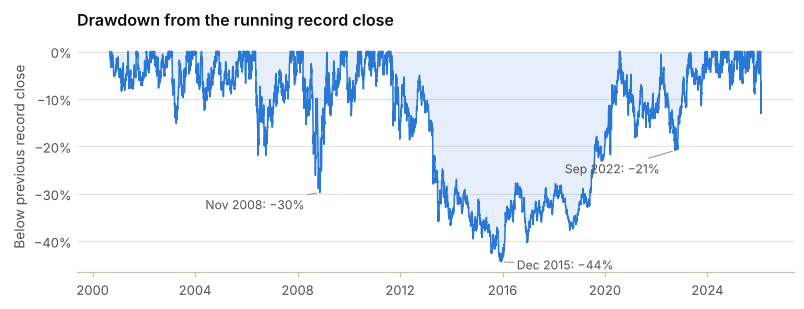

In [37]:
running_peak = close.cummax()
drawdown = (close / running_peak - 1) * 100

episodes, start = [], None
for day, c, m in zip(close.index, close.to_numpy(), running_peak.to_numpy()):
    if c < m:
        if start is None:
            start, peak_value, low, low_day = day, m, c, day
        if c < low:
            low, low_day = c, day
    elif start is not None:
        episodes.append((peak_value, low, start, low_day, day))
        start = None
if start is not None:
    episodes.append((peak_value, low, start, low_day, pd.NaT))
dd_table = pd.DataFrame(episodes, columns=["peak_price", "trough_price", "first_day_below_peak", "trough_date", "recovered_on"])
dd_table["peak_date"] = [close[:d].idxmax() for d in dd_table["first_day_below_peak"]]
dd_table["depth_%"] = (dd_table["trough_price"] / dd_table["peak_price"] - 1) * 100
dd_table["days_peak_to_recovery"] = (dd_table["recovered_on"] - dd_table["peak_date"]).dt.days
dd_table = dd_table.sort_values("depth_%").head(6)[["peak_date", "peak_price", "trough_date", "trough_price", "depth_%", "recovered_on", "days_peak_to_recovery"]]
display(dd_table.round({"peak_price": 1, "trough_price": 1, "depth_%": 1}))
dd_table.to_csv(RES_DIR / "drawdowns.csv", index=False)
print(f"Share of days below a previous record close: {(drawdown < 0).mean():.1%} | more than 10% below: {(drawdown < -10).mean():.1%}")
RESULTS["drawdown"] = {
    "max_depth": float(drawdown.min()), "max_trough": drawdown.idxmin().date().isoformat(),
    "share_below_peak": float((drawdown < 0).mean() * 100), "share_below_10": float((drawdown < -10).mean() * 100),
    "top": [{"peak_date": r["peak_date"].date().isoformat(), "peak": float(r["peak_price"]),
             "trough_date": r["trough_date"].date().isoformat(), "trough": float(r["trough_price"]), "depth": float(r["depth_%"]),
             "recovered": None if pd.isna(r["recovered_on"]) else r["recovered_on"].date().isoformat(),
             "days": None if pd.isna(r["days_peak_to_recovery"]) else int(r["days_peak_to_recovery"])}
            for r in dd_table.to_dict("records")],
    "current": float(drawdown.iloc[-1]),
}

fig, ax = plt.subplots(figsize=(7.2, 2.7), constrained_layout=True)
ax.fill_between(drawdown.index, drawdown, 0, color=BLUE, alpha=0.12, linewidth=0)
ax.plot(drawdown.index, drawdown, color=BLUE, lw=1.0)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Below previous record close")
worst = drawdown.idxmin()
note(ax, f"Dec 2015: \u2212{abs(drawdown.min()):.0f}%", (worst, drawdown.min()), (10, -2))
note(ax, f"Nov 2008: \u2212{abs(drawdown['2008'].min()):.0f}%", (drawdown["2008"].idxmin(), drawdown["2008"].min()), (-10, -8), ha="right")
note(ax, f"Sep 2022: \u2212{abs(drawdown['2022'].min()):.0f}%", (drawdown["2022"].idxmin(), drawdown["2022"].min()), (-10, -12), ha="right")
ax.set_title("Drawdown from the running record close")
save(fig, "fig13_drawdown")

The long-run gain hides long losing stretches. From the August 2011 peak gold lost 44% over four years and
took until July 2020, almost nine years, to set a new record. The 2008 drawdown was shallower (-30%) and
was made up within 18 months. On 94% of days gold closed below an earlier record, and on 45% of days it
was more than 10% below one.

### 4.8 Trend: price against its moving averages

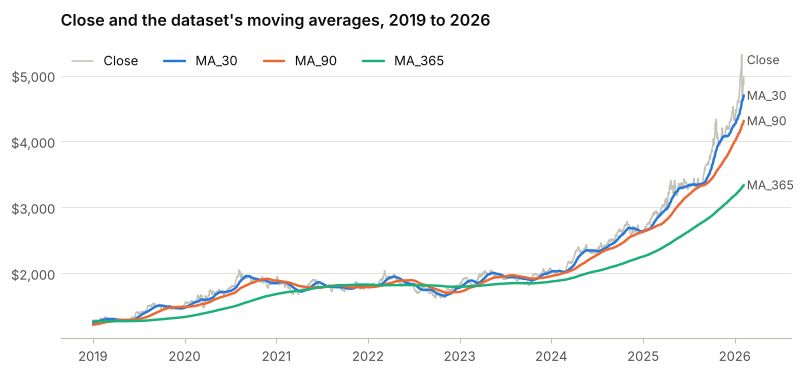

,days_above_%,next_day_mean_above_%,next_day_mean_below_%,up_days_above_%,up_days_below_%,Welch_t_p,Mann_Whitney_p
average,,,,,,,
MA_30,56.5720,0.0310,0.0660,52.6990,53.0990,0.2130,0.4290
MA_90,64.3100,0.0360,0.0650,53.3980,52.2260,0.3180,0.7470
MA_365,76.7200,0.0540,0.0250,54.0610,49.9640,0.3920,0.0060


Close is 49% above MA_365 on the last day; the widest gap in the sample is 61% on 2026-01-29


In [38]:
window = slice("2019-01-01", None)
fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
ax.plot(close[window].index, close[window], color=CONTEXT, lw=1.0, label="Close")
for col, color in [("MA_30", BLUE), ("MA_90", ORANGE), ("MA_365", AQUA)]:
    s = df.loc[window, col]
    ax.plot(s.index, s, color=color, lw=1.6, label=col)
    ax.text(s.index[-1] + pd.Timedelta(days=12), s.iloc[-1], col, color=INK_2, fontsize=8, va="center")
ax.text(close.index[-1] + pd.Timedelta(days=12), close.iloc[-1] + 260, "Close", color=INK_2, fontsize=8, va="center")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlim(right=close.index[-1] + pd.Timedelta(days=190))
ax.legend(loc="upper left", ncol=4, handlelength=1.6)
ax.set_title("Close and the dataset's moving averages, 2019 to 2026")
save(fig, "fig14_moving_averages")

next_ret = df["log_return"].shift(-1)
rows = []
for col in ["MA_30", "MA_90", "MA_365"]:
    ok = df[col].notna() & next_ret.notna()
    above = df["Close"] > df[col]
    x, y = next_ret[ok & above], next_ret[ok & ~above]
    rows.append({"average": col, "days_above_%": above[ok].mean() * 100,
                 "next_day_mean_above_%": x.mean(), "next_day_mean_below_%": y.mean(),
                 "up_days_above_%": (x > 0).mean() * 100, "up_days_below_%": (y > 0).mean() * 100,
                 "Welch_t_p": stats.ttest_ind(x, y, equal_var=False).pvalue,
                 "Mann_Whitney_p": stats.mannwhitneyu(x, y).pvalue})
trend_table = pd.DataFrame(rows).set_index("average")
display(trend_table.round(3))
trend_table.to_csv(RES_DIR / "trend_signal.csv")
RESULTS["trend"] = {k: {c: float(v) for c, v in row.items()} for k, row in trend_table.to_dict("index").items()}
gap_now = (close.iloc[-1] / df["MA_365"].iloc[-1] - 1) * 100
RESULTS["trend"]["gap_to_ma365_last"] = float(gap_now)
RESULTS["trend"]["max_gap_to_ma365"] = float(((close / df["MA_365"] - 1) * 100).max())
gap_series = (close / df["MA_365"] - 1) * 100
RESULTS["trend"]["max_gap_date"] = gap_series.idxmax().date().isoformat()
print(f"Close is {gap_now:.0f}% above MA_365 on the last day; the widest gap in the sample is {gap_series.max():.0f}% on {gap_series.idxmax().date()}")

Close sits above `MA_365` on 77% of days, which is what an upward-drifting series does. Being above or
below an average says little about the next day. The mean next-day return differs slightly between the
two states, and no Welch test comes close to 5%. Only the share of up days is a little higher above
`MA_365` (54.1% against 50.0%).

The chart also shows how far the 2025 rally ran ahead of its own history. At the record close of 29
January 2026 the price stood 61% above `MA_365`, the widest gap in the sample, and it is still 49% above
on the last day of the file.

### 4.9 Correlation analysis

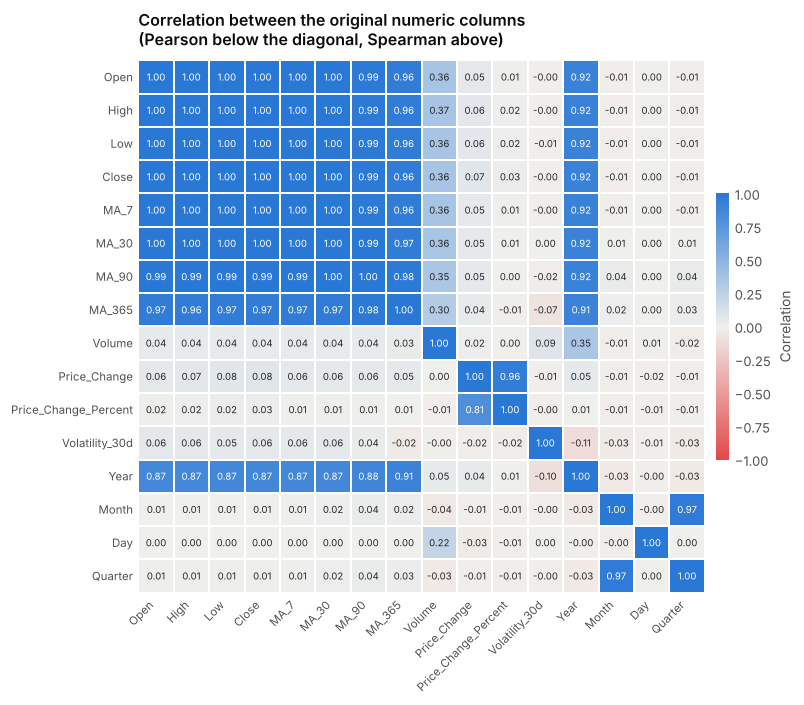

Lowest Pearson correlation among the eight price-level columns: 0.9645 | among Open, High, Low, Close, MA_7: 0.99951
Volume vs Day of month: Pearson 0.22
Close vs Year: Pearson 0.87, Spearman 0.92
Price_Change_Percent vs Close: 0.030 | vs Volume: 0.003
Volatility_30d vs Close: Pearson 0.06, Spearman -0.00
Volume vs Close: Pearson 0.04, Spearman 0.36


In [39]:
numeric_cols = ["Open", "High", "Low", "Close", "MA_7", "MA_30", "MA_90", "MA_365", "Volume",
                "Price_Change", "Price_Change_Percent", "Volatility_30d", "Year", "Month", "Day", "Quarter"]
pearson = df[numeric_cols].corr(method="pearson")
spearman = df[numeric_cols].corr(method="spearman")
upper = np.triu_indices(len(numeric_cols), k=1)
mixed = pearson.to_numpy().copy()
mixed[upper] = spearman.to_numpy()[upper]
combined = pd.DataFrame(mixed, index=numeric_cols, columns=numeric_cols)
combined.to_csv(RES_DIR / "correlation_raw_columns.csv")

fig, ax = plt.subplots(figsize=(7.2, 6.3), constrained_layout=True)
sns.heatmap(combined, cmap=DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.3},
            linewidths=1.0, linecolor="white", cbar_kws={"shrink": 0.5, "label": "Correlation", "pad": 0.02}, ax=ax)
ax.tick_params(axis="both", length=0, labelsize=7.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Correlation between the original numeric columns\n(Pearson below the diagonal, Spearman above)")
save(fig, "fig15_correlation_raw")

price_block = ["Open", "High", "Low", "Close", "MA_7", "MA_30", "MA_90", "MA_365"]
off_diag = pearson.loc[price_block, price_block].to_numpy()[np.triu_indices(len(price_block), k=1)]
core = ["Open", "High", "Low", "Close", "MA_7"]
core_min = pearson.loc[core, core].to_numpy()[np.triu_indices(len(core), k=1)].min()
print(f"Lowest Pearson correlation among the eight price-level columns: {off_diag.min():.4f} | among Open, High, Low, Close, MA_7: {core_min:.5f}")
print(f"Volume vs Day of month: Pearson {pearson.loc['Volume', 'Day']:.2f}")
print(f"Close vs Year: Pearson {pearson.loc['Close', 'Year']:.2f}, Spearman {spearman.loc['Close', 'Year']:.2f}")
print(f"Price_Change_Percent vs Close: {pearson.loc['Price_Change_Percent', 'Close']:.3f} | vs Volume: {spearman.loc['Price_Change_Percent', 'Volume']:.3f}")
print(f"Volatility_30d vs Close: Pearson {pearson.loc['Volatility_30d', 'Close']:.2f}, Spearman {spearman.loc['Volatility_30d', 'Close']:.2f}")
print(f"Volume vs Close: Pearson {pearson.loc['Volume', 'Close']:.2f}, Spearman {spearman.loc['Volume', 'Close']:.2f}")
RESULTS["correlation"] = {
    "min_price_block": float(off_diag.min()), "min_core_block": float(core_min), "volume_day_pearson": float(pearson.loc["Volume", "Day"]),
    "close_year_pearson": float(pearson.loc["Close", "Year"]), "close_year_spearman": float(spearman.loc["Close", "Year"]),
    "pct_close": float(pearson.loc["Price_Change_Percent", "Close"]),
    "vol30_close_pearson": float(pearson.loc["Volatility_30d", "Close"]), "vol30_close_spearman": float(spearman.loc["Volatility_30d", "Close"]),
    "volume_close_pearson": float(pearson.loc["Volume", "Close"]), "volume_close_spearman": float(spearman.loc["Volume", "Close"]),
}

The eight price-level columns (Open, High, Low, Close and the four moving averages) are correlated at
0.96 or more with each other, and Open, High, Low, Close and `MA_7` above 0.999. They are one variable
written eight times. Feeding them to a regression together would give unstable coefficients, which is
one more reason our features are *ratios* between these columns and not the columns themselves.

The daily change columns are close to uncorrelated with everything. `Volume` is the column where Pearson
and Spearman disagree most (0.04 against 0.36 with Close), which is what a few enormous roll days do to a
linear measure. Its only notable Pearson correlation is with the day of the month (0.22), the roll
calendar again.

Next, the correlation of each engineered feature with two of the targets: tomorrow's return and the
size of tomorrow's move.

|rho| needed for p < 0.05 with n = 6,018: 0.025
Largest |rho| with tomorrow's return: ma90_vs_ma365 0.051
Largest |rho| with the size of tomorrow's move: vol_30 0.224


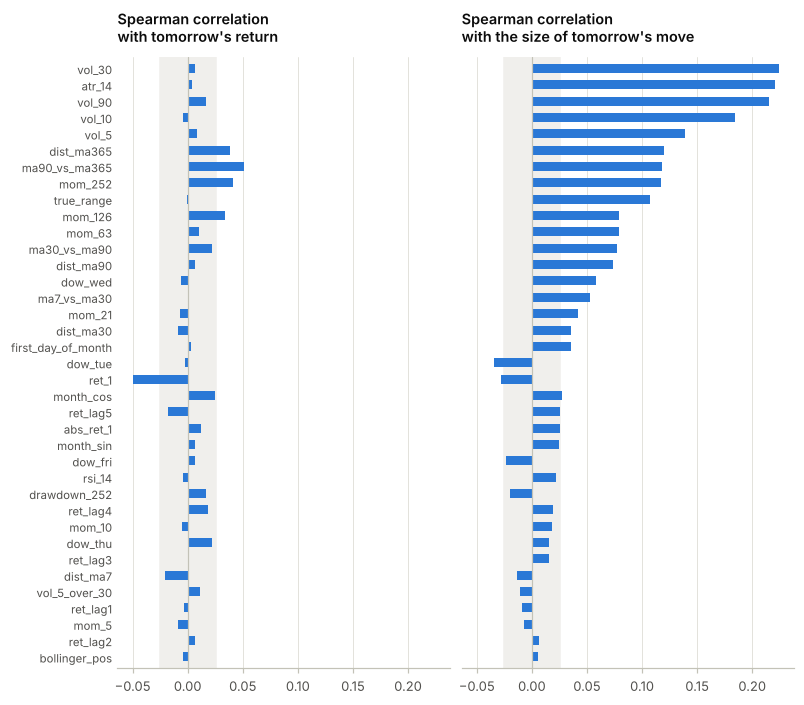

In [40]:
ft = pd.DataFrame({
    "with tomorrow's return": model_df[FEATURES].corrwith(model_df["y_ret"], method="spearman"),
    "with the size of tomorrow's move": model_df[FEATURES].corrwith(model_df["y_abs"], method="spearman"),
})
order = ft["with the size of tomorrow's move"].abs().sort_values().index
ft = ft.loc[order]
ft.to_csv(RES_DIR / "feature_target_correlation.csv")
crit = 1.96 / np.sqrt(len(model_df))
print(f"|rho| needed for p < 0.05 with n = {len(model_df):,}: {crit:.3f}")
print("Largest |rho| with tomorrow's return:", ft.iloc[:, 0].abs().idxmax(), round(ft.iloc[:, 0].abs().max(), 3))
print("Largest |rho| with the size of tomorrow's move:", ft.iloc[:, 1].abs().idxmax(), round(ft.iloc[:, 1].abs().max(), 3))
RESULTS["feature_target"] = {
    "crit": float(crit),
    "max_ret": [ft.iloc[:, 0].abs().idxmax(), float(ft.iloc[:, 0].abs().max())],
    "max_abs": [ft.iloc[:, 1].abs().idxmax(), float(ft.iloc[:, 1].abs().max())],
    "n_sig_ret": int((ft.iloc[:, 0].abs() > crit).sum()), "n_sig_abs": int((ft.iloc[:, 1].abs() > crit).sum()),
    "n_above_01_abs": int((ft.iloc[:, 1].abs() > 0.1).sum()),
}

fig, axes = plt.subplots(1, 2, figsize=(7.2, 6.3), sharey=True, sharex=True, constrained_layout=True)
ypos = np.arange(len(ft))
for ax, col in zip(axes, ft.columns):
    ax.axvspan(-crit, crit, color=NEUTRAL, zorder=0)
    ax.barh(ypos, ft[col], height=0.55, color=BLUE)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.set_title("Spearman correlation\n" + col, fontsize=9.5)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(ft.index, fontsize=7.5)
axes[0].set_ylim(-0.7, len(ft) - 0.3)
save(fig, "fig16_feature_target_correlation")

This chart previews the modelling results. On the left, the largest rank correlation with tomorrow's
return is 0.05, and most features sit inside the grey band where a correlation cannot be told apart from
zero. The few that leave it are today's return (slightly negative) and three long-run trend measures
(slightly positive). A correlation of 0.05 corresponds to a quarter of one percent of the variance.
On the right, the volatility features reach 0.14 to 0.22 with the size of tomorrow's move.

### 4.10 Does today's volatility say anything about tomorrow?

,mean_abs_move_%,up_days_%,vol_30_range
vol_30,,,
Q1\ncalmest,0.5783,53.4884,0.43-0.73
Q2,0.6792,53.7822,0.73-0.88
Q3,0.7193,53.4053,0.88-1.02
Q4,0.8250,54.9460,1.02-1.25
Q5\nmost volatile,1.1655,49.9169,1.25-3.21


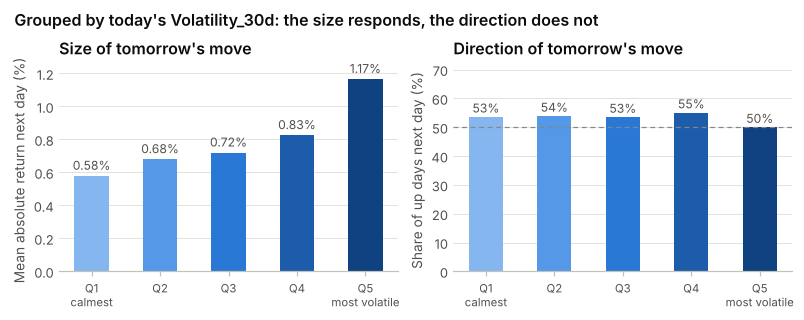

In [41]:
q = pd.qcut(model_df["vol_30"], 5, labels=["Q1\ncalmest", "Q2", "Q3", "Q4", "Q5\nmost volatile"])
vol_quintiles = pd.DataFrame({
    "mean_abs_move_%": model_df.groupby(q, observed=True)["y_abs"].mean(),
    "up_days_%": model_df.groupby(q, observed=True)["y_dir"].mean() * 100,
    "vol_30_range": model_df.groupby(q, observed=True)["vol_30"].agg(lambda s: f"{s.min():.2f}-{s.max():.2f}"),
})
display(vol_quintiles)
vol_quintiles.to_csv(RES_DIR / "volatility_quintiles.csv")
RESULTS["vol_quintiles"] = {"abs": [float(v) for v in vol_quintiles["mean_abs_move_%"]], "up": [float(v) for v in vol_quintiles["up_days_%"]]}

fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 2.8), constrained_layout=True)
ramp = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
a.bar(vol_quintiles.index, vol_quintiles["mean_abs_move_%"], width=0.5, color=ramp)
for i, v in enumerate(vol_quintiles["mean_abs_move_%"]):
    a.text(i, v + 0.02, f"{v:.2f}%", ha="center", va="bottom", fontsize=8, color=INK_2)
a.set_ylabel("Mean absolute return next day (%)")
a.set_title("Size of tomorrow's move")
b.bar(vol_quintiles.index, vol_quintiles["up_days_%"], width=0.5, color=ramp)
for i, v in enumerate(vol_quintiles["up_days_%"]):
    b.text(i, v + 0.6, f"{v:.0f}%", ha="center", va="bottom", fontsize=8, color=INK_2)
b.axhline(50, color=MUTED, lw=0.8, ls=(0, (4, 3)))
b.set_ylim(0, 70)
b.set_ylabel("Share of up days next day (%)")
b.set_title("Direction of tomorrow's move")
for ax in (a, b):
    ax.tick_params(axis="x", labelsize=7.5)
fig.suptitle("Grouped by today's Volatility_30d: the size responds, the direction does not", x=0.01, ha="left",
             fontsize=10.5, fontweight="semibold")
save(fig, "fig17_volatility_quintiles")

After the calmest fifth of days the next move averages 0.58%. After the most volatile fifth it averages
1.17%, twice as much. The share of up days stays between 50% and 55% in all five groups.

### 4.11 What the EDA tells us before we model

* The price level is non-stationary and almost perfectly autocorrelated. Any model scored on the level
  will report an R-squared near 1, whether or not it has learned anything.
* Daily returns are stationary, fat-tailed, slightly left-skewed and essentially uncorrelated with their
  own past and with all 37 features.
* Calendar effects on the average return are not statistically reliable.
* The size of the move is persistent and related to recent volatility.

So we expect models to struggle with questions 2 and 3 and to do better on question 4. The next sections
test that.

## 5. Model development

### 5.1 Framing the problem, and three ways to get it wrong

"Predict the gold price" can be set up in ways that produce impressive scores for the wrong reasons.
Before building the real models we ran the tempting versions on purpose, to see how they fail.

In [42]:
def price_scores(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    err = actual - predicted
    return {"RMSE_$": np.sqrt(np.mean(err ** 2)), "MAE_$": np.mean(np.abs(err)),
            "MAPE_%": np.mean(np.abs(err) / actual) * 100, "R2": r2_score(actual, predicted)}


levels = df[["Open", "High", "Low", "Close", "MA_7", "MA_30", "MA_90", "MA_365", "Volatility_30d"]].copy()
levels["next_close"] = df["Close"].shift(-1)
levels = levels.dropna()
lv_train, lv_test = levels[:"2021-12-31"], levels["2022-01-01":]
same_day = ["Open", "High", "Low", "MA_7", "MA_30", "MA_90", "MA_365", "Volatility_30d"]
level_cols = same_day + ["Close"]
pitfalls = {}

# (a) Same-day leak: "predict" today's close from today's other columns
leak = LinearRegression().fit(lv_train[same_day], lv_train["Close"])
pitfalls["A. Today's Close from today's Open, High, Low and averages"] = {
    "split": "chronological", **price_scores(lv_test["Close"], leak.predict(lv_test[same_day]))}

# (b) Shuffled split: tomorrow's close from today's levels, rows mixed at random
Xa, Xb, ya, yb = train_test_split(levels[level_cols], levels["next_close"], test_size=0.2, shuffle=True, random_state=SEED)
rf_shuffled = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(Xa, ya)
pitfalls["B. Random forest on price levels, shuffled 80/20 split"] = {"split": "shuffled", **price_scores(yb, rf_shuffled.predict(Xb))}
pitfalls["   Naive forecast on the same shuffled rows"] = {"split": "shuffled", **price_scores(yb, Xb["Close"])}

# (c) Honest split, but the target is still the price level
rf_levels = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(lv_train[level_cols], lv_train["next_close"])
rf_levels_pred = pd.Series(rf_levels.predict(lv_test[level_cols]), index=lv_test.index)
pitfalls["C. Random forest on price levels, chronological split"] = {"split": "chronological", **price_scores(lv_test["next_close"], rf_levels_pred)}
lin_levels = LinearRegression().fit(lv_train[level_cols], lv_train["next_close"])
pitfalls["   Linear regression on price levels, chronological split"] = {"split": "chronological", **price_scores(lv_test["next_close"], lin_levels.predict(lv_test[level_cols]))}
pitfalls["   Naive forecast (tomorrow = today), chronological split"] = {"split": "chronological", **price_scores(lv_test["next_close"], lv_test["Close"])}

pitfall_table = pd.DataFrame(pitfalls).T
display(pitfall_table)
pitfall_table.to_csv(RES_DIR / "pitfalls.csv")
train_max_close = float(lv_train["Close"].max())
print(f"Highest close in the training years: ${train_max_close:,.1f} | highest random-forest prediction in the test years: ${rf_levels_pred.max():,.1f}")
RESULTS["pitfalls"] = {k.strip(): {c: (float(v) if c != "split" else v) for c, v in row.items()} for k, row in pitfalls.items()}
RESULTS["pitfalls"]["train_max_close"] = train_max_close
RESULTS["pitfalls"]["rf_levels_max_pred"] = float(rf_levels_pred.max())

,split,RMSE_$,MAE_$,MAPE_%,R2
"A. Today's Close from today's Open, High, Low and averages",chronological,11.1987,6.2101,0.2416,0.9998
"B. Random forest on price levels, shuffled 80/20 split",shuffled,23.2839,12.1476,0.8956,0.9991
Naive forecast on the same shuffled rows,shuffled,26.7216,11.5260,0.8275,0.9988
"C. Random forest on price levels, chronological split",chronological,926.5641,557.4601,16.9033,-0.4015
"Linear regression on price levels, chronological split",chronological,37.9412,21.2594,0.7980,0.9977
"Naive forecast (tomorrow = today), chronological split",chronological,37.5995,21.0146,0.7922,0.9977


Highest close in the training years: $2,051.5 | highest random-forest prediction in the test years: $1,958.3


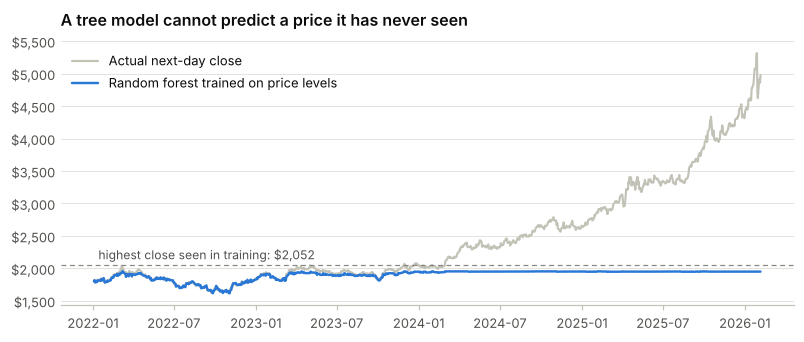

In [43]:
fig, ax = plt.subplots(figsize=(7.2, 3.0), constrained_layout=True)
ax.plot(lv_test.index, lv_test["next_close"], color=CONTEXT, lw=1.4, label="Actual next-day close")
ax.plot(rf_levels_pred.index, rf_levels_pred, color=BLUE, lw=1.6, label="Random forest trained on price levels")
ax.axhline(train_max_close, color=MUTED, lw=0.8, ls=(0, (4, 3)))
ax.text(lv_test.index[8], train_max_close + 90, f"highest close seen in training: ${train_max_close:,.0f}", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(dollars)
ax.legend(loc="upper left")
ax.set_title("A tree model cannot predict a price it has never seen")
save(fig, "fig18_level_model_failure")

**A. The same-day leak.** Regressing today's Close on today's Open, High, Low and moving averages gives
an R-squared that rounds to 1. It is not a forecast. High and Low bracket the Close, and `MA_7` contains
today's Close inside its own average, so the answer is in the inputs.

**B. The shuffled split.** With rows mixed at random, the forest is tested on days whose neighbours (the
day before and the day after) are in its training set. It only has to interpolate, and it appears to
beat the naive forecast ($23 against $27 RMSE on the same rows).

**C. The price level as target.** The same forest on an honest chronological split has an RMSE of $927.
A tree can only output averages of training targets, so its predictions stop near the highest price it
was trained on while the real price climbs past $5,000. Linear regression on levels avoids that failure
and lands on the naive forecast ($37.94 against $37.60), which is all it can learn from columns that are
copies of the price.

**What we do instead.** All our models predict *changes* (log returns), which are stationary, from
features measured at the close of the previous day, on a chronological split. A predicted return is
turned back into a price with `price(t+1) = Close(t) x exp(return / 100)`.

We set three tasks on the same 37 features:

| Task | Target | Type | Baseline to beat |
|---|---|---|---|
| A | tomorrow's close (through tomorrow's log return) | regression | naive: tomorrow = today |
| B | tomorrow up or down | classification | always predict "up" |
| C | size of tomorrow's move, the absolute return | regression | the dataset's own `Volatility_30d` and an EWMA |

### 5.2 Train, validation and test

In [44]:
TRAIN_END, TEST_START = "2021-12-31", "2022-01-01"
train, test = model_df[:TRAIN_END], model_df[TEST_START:]
X_train, X_test = train[FEATURES], test[FEATURES]
tscv = TimeSeriesSplit(n_splits=5)

position = pd.Series(np.arange(len(df)), index=df.index)
test_target_dates = df.index[position[test.index].to_numpy() + 1]     # the day each test forecast is for

split_table = pd.DataFrame({
    "rows": [len(train), len(test)],
    "share_%": [len(train) / len(model_df) * 100, len(test) / len(model_df) * 100],
    "from": [train.index.min().date(), test.index.min().date()],
    "to": [train.index.max().date(), test.index.max().date()],
    "close_min_$": [train["close"].min(), test["close"].min()],
    "close_max_$": [train["close"].max(), test["close"].max()],
    "std_daily_return_%": [train["y_ret"].std(), test["y_ret"].std()],
    "up_days_%": [train["y_dir"].mean() * 100, test["y_dir"].mean() * 100],
}, index=["train", "test"])
display(split_table.round(2))
split_table.to_csv(RES_DIR / "split.csv")
folds = [(train.index[tr][0].date(), train.index[tr][-1].date(), train.index[va][0].date(), train.index[va][-1].date(), len(tr), len(va))
         for tr, va in tscv.split(X_train)]
fold_table = pd.DataFrame(folds, columns=["fit_from", "fit_to", "validate_from", "validate_to", "fit_rows", "validate_rows"],
                          index=[f"fold {i}" for i in range(1, 6)])
display(fold_table)
fold_table.to_csv(RES_DIR / "cv_folds.csv")
RESULTS["split"] = {
    "train_rows": int(len(train)), "test_rows": int(len(test)), "train_pct": float(len(train) / len(model_df) * 100),
    "test_pct": float(len(test) / len(model_df) * 100),
    "train_from": str(train.index.min().date()), "train_to": str(train.index.max().date()),
    "test_from": str(test.index.min().date()), "test_to": str(test.index.max().date()),
    "test_target_from": str(test_target_dates.min().date()), "test_target_to": str(test_target_dates.max().date()),
    "train_std": float(train["y_ret"].std()), "test_std": float(test["y_ret"].std()),
    "train_up": float(train["y_dir"].mean() * 100), "test_up": float(test["y_dir"].mean() * 100),
    "train_close_max": float(train["close"].max()), "test_close_max": float(test["next_close"].max()),
    "fold_validate_rows": int(folds[0][5]),
}

,rows,share_%,from,to,close_min_$,close_max_$,std_daily_return_%,up_days_%
train,4989,82.9000,2002-02-20,2021-12-31,289.9000,"2,051.5000",1.1200,52.6000
test,1029,17.1000,2022-01-03,2026-02-05,"1,623.3000","5,318.4000",1.1300,55.5900


,fit_from,fit_to,validate_from,validate_to,fit_rows,validate_rows
fold 1,2002-02-20,2005-06-23,2005-06-24,2008-10-14,834,831
fold 2,2002-02-20,2008-10-14,2008-10-15,2012-02-01,1665,831
fold 3,2002-02-20,2012-02-01,2012-02-02,2015-05-22,2496,831
fold 4,2002-02-20,2015-05-22,2015-05-26,2018-09-13,3327,831
fold 5,2002-02-20,2018-09-13,2018-09-14,2021-12-31,4158,831


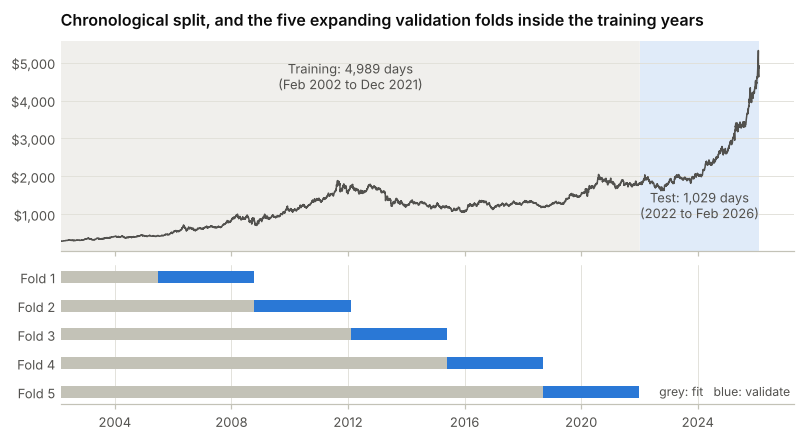

In [45]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.2, 3.9), sharex=True, constrained_layout=True,
                                  gridspec_kw={"height_ratios": [1.5, 1]})
top.plot(model_df.index, model_df["close"], color=INK_2, lw=1.0)
top.axvspan(train.index[0], train.index[-1], color=NEUTRAL, zorder=0)
top.axvspan(test.index[0], test.index[-1], color=BLUE, alpha=0.14, zorder=0, linewidth=0)
top.text(train.index[len(train) // 2], 4300, f"Training: {len(train):,} days\n(Feb 2002 to Dec 2021)", ha="center", fontsize=8.5, color=INK_2)
top.text(test.index[len(test) // 2], 900, f"Test: {len(test):,} days\n(2022 to Feb 2026)", ha="center", fontsize=8.5, color=INK_2)
top.yaxis.set_major_formatter(dollars)
top.set_title("Chronological split, and the five expanding validation folds inside the training years")
for i, (tr, va) in enumerate(tscv.split(X_train)):
    y = 5 - i
    bottom.barh(y, (train.index[tr][-1] - train.index[tr][0]).days, left=mpl.dates.date2num(train.index[tr][0]), height=0.42, color=CONTEXT)
    bottom.barh(y, (train.index[va][-1] - train.index[va][0]).days, left=mpl.dates.date2num(train.index[va][0]), height=0.42, color=BLUE)
bottom.set_yticks(range(1, 6))
bottom.set_yticklabels([f"Fold {i}" for i in range(5, 0, -1)])
bottom.grid(axis="y", visible=False)
bottom.grid(axis="x", visible=True)
bottom.xaxis_date()
bottom.text(0.995, 0.06, "grey: fit   blue: validate", transform=bottom.transAxes, ha="right", fontsize=8, color=INK_2)
save(fig, "fig19_split_and_folds")

* **Training set:** 20 February 2002 to 31 December 2021 (4,989 days, 83%).
* **Test set:** 3 January 2022 to 5 February 2026 (1,029 days, 17%). It plays no part in tuning and is used only for the final scores.
* **Validation:** inside the training years we use scikit-learn's `TimeSeriesSplit` with five folds. Each
  fold fits on everything before a date and validates on the 831 days after it, so a model is never
  tuned on data from before its training window.
* **Scaling:** `StandardScaler` sits inside a `Pipeline` with the model, so its mean and standard
  deviation are learned from the fitting part of each fold only.

The split is hard on the models, and that is deliberate. The test years contain prices up to $5,318, far
outside the training range (maximum $2,052), and the largest one-day fall in the whole file.

### 5.3 Models, tuning and scoring

In [46]:
def tune(estimator, grid, y, scoring):
    """Grid search with expanding-window cross-validation on the training set."""
    t0 = time.time()
    search = GridSearchCV(estimator, grid, cv=tscv, scoring=scoring, n_jobs=-1, refit=True)
    search.fit(X_train, y)
    search.seconds_ = time.time() - t0
    return search


def scaled(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])


def dm_test(err_reference, err_model):
    """Diebold-Mariano test on squared errors (one-step forecasts, Harvey-Leybourne-Newbold correction).
    A positive statistic means the model's errors are smaller than the reference's."""
    d = np.asarray(err_reference) ** 2 - np.asarray(err_model) ** 2
    n = len(d)
    statistic = d.mean() / np.sqrt(d.var(ddof=0) / n) * np.sqrt((n - 1) / n)
    return statistic, 2 * stats.t.sf(abs(statistic), df=n - 1)


def cv_rmse_of_constant(y, how):
    """RMSE of a no-model forecast on the same validation folds the grid search uses."""
    out = []
    for tr, va in tscv.split(y):
        guess = 0.0 if how == "zero" else y.iloc[tr].mean()
        out.append(np.sqrt(np.mean((y.iloc[va] - guess) ** 2)))
    return float(np.mean(out))


REG_GRID = {
    "Linear Regression": (scaled(LinearRegression()), {}),
    "Ridge": (scaled(Ridge()), {"model__alpha": [1, 10, 100, 1_000, 10_000, 100_000]}),
    "Lasso": (scaled(Lasso(max_iter=50_000)), {"model__alpha": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}),
    "Random Forest": (RandomForestRegressor(n_estimators=200, max_features=0.33, n_jobs=1, random_state=SEED),
                      {"max_depth": [2, 4, 8], "min_samples_leaf": [20, 50, 100, 200]}),
    "XGBoost": (XGBRegressor(n_estimators=300, subsample=0.8, colsample_bytree=0.8, n_jobs=1, random_state=SEED),
                {"max_depth": [1, 2, 3], "learning_rate": [0.005, 0.01, 0.03], "min_child_weight": [20, 100]}),
}
CLF_GRID = {
    "Logistic Regression": (scaled(LogisticRegression(max_iter=5_000)), {"model__C": [0.0001, 0.001, 0.01, 0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_features=0.33, n_jobs=1, random_state=SEED),
                      {"max_depth": [2, 4, 8], "min_samples_leaf": [50, 100, 200]}),
    "XGBoost": (XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8, n_jobs=1, random_state=SEED),
                {"max_depth": [1, 2, 3], "learning_rate": [0.005, 0.01, 0.03], "min_child_weight": [20, 100]}),
}
grid_sizes = {name: int(np.prod([len(v) for v in grid.values()])) if grid else 1 for name, (_, grid) in REG_GRID.items()}
print("Hyperparameter combinations per model (regression):", grid_sizes)

Hyperparameter combinations per model (regression): {'Linear Regression': 1, 'Ridge': 6, 'Lasso': 6, 'Random Forest': 12, 'XGBoost': 18}


| Model | Why it is in the comparison | What we tune |
|---|---|---|
| Naive, drift, ARIMA | The classical benchmarks for a price series. Naive says tomorrow equals today; drift adds the average training return; ARIMA adds short-term autocorrelation. | ARIMA order (p, q) by AIC |
| Linear regression | The simplest model that uses all 37 features. No tuning, so it shows what happens without regularisation. | nothing |
| Ridge | Linear, with coefficients shrunk toward zero. Suited to our features, many of which are correlated. | penalty `alpha` |
| Lasso | Linear, and able to set coefficients exactly to zero, so it also tells us which features it keeps. | penalty `alpha` |
| Random forest | Averages many trees. Can pick up non-linear effects and interactions without being told about them. | tree depth, minimum leaf size |
| XGBoost | Boosted trees, usually the strongest model on tabular data. | tree depth, learning rate, minimum child weight |
| Logistic regression | The linear model for the up/down task. | inverse penalty `C` |

Every tuned model goes through the same `GridSearchCV` with the five time-ordered folds. Regression
models are tuned on RMSE and classifiers on ROC-AUC. After tuning, the best setting is refitted on the
whole training set and scored once on the test set.

**Scoring.** For task A we report errors in dollars (RMSE, MAE), in percent (MAPE) and the R-squared of
the price. Because the R-squared of a price level is misleading, the numbers we judge by are the RMSE
relative to the two no-feature forecasts (naive and drift) and a Diebold-Mariano test of whether a
difference is more than luck.
Task B uses accuracy, precision, recall, F1 and ROC-AUC. Task C uses RMSE, MAE, R-squared against the
training mean, and the Spearman correlation between predicted and realised size.

### 5.4 Task A: tomorrow's closing price

In [47]:
y_train_ret, y_test_ret = train["y_ret"], test["y_ret"]

search_A = {}
for name, (estimator, grid) in REG_GRID.items():
    search_A[name] = tune(estimator, grid, y_train_ret, "neg_root_mean_squared_error")
    print(f"{name:18s} CV RMSE {-search_A[name].best_score_:.4f}  best {search_A[name].best_params_}  ({search_A[name].seconds_:.0f}s)")

cv_naive_A = cv_rmse_of_constant(y_train_ret, "zero")
cv_drift_A = cv_rmse_of_constant(y_train_ret, "mean")
print(f"On the same folds: naive {cv_naive_A:.4f} | drift {cv_drift_A:.4f}")

Linear Regression  CV RMSE 1.1883  best {}  (1s)
Ridge              CV RMSE 1.1376  best {'model__alpha': 100000}  (0s)


Lasso              CV RMSE 1.1374  best {'model__alpha': 0.1}  (0s)


Random Forest      CV RMSE 1.1390  best {'max_depth': 2, 'min_samples_leaf': 200}  (25s)


XGBoost            CV RMSE 1.1401  best {'learning_rate': 0.005, 'max_depth': 1, 'min_child_weight': 100}  (6s)
On the same folds: naive 1.1372 | drift 1.1374


In [48]:
# ARIMA on the return series: choose (p, q) by AIC on the training years, then forecast one step ahead through the test years
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    aic = {}
    for p in range(3):
        for q_ in range(3):
            aic[(p, q_)] = ARIMA(y_train_ret.to_numpy(), order=(p, 0, q_), trend="c").fit().aic
    arima_order = min(aic, key=aic.get)
    arima_fit = ARIMA(y_train_ret.to_numpy(), order=(arima_order[0], 0, arima_order[1]), trend="c").fit()
    arima_all = arima_fit.append(y_test_ret.to_numpy(), refit=False)
    arima_pred = arima_all.predict(start=len(train), end=len(train) + len(test) - 1)
print("AIC by (p, q):", {k: round(v, 1) for k, v in aic.items()})
print("Chosen order:", arima_order, "| AIC spread across the nine models:", round(max(aic.values()) - min(aic.values()), 1))

AIC by (p, q): {(0, 0): np.float64(15329.4), (0, 1): np.float64(15331.1), (0, 2): np.float64(15332.7), (1, 0): np.float64(15331.1), (1, 1): np.float64(15327.8), (1, 2): np.float64(15332.7), (2, 0): np.float64(15332.7), (2, 1): np.float64(15334.7), (2, 2): np.float64(15336.7)}
Chosen order: (1, 1) | AIC spread across the nine models: 8.9


In [49]:
pred_A = {
    "Naive (tomorrow = today)": np.zeros(len(test)),
    "Drift (training mean return)": np.full(len(test), y_train_ret.mean()),
    f"ARIMA{(arima_order[0], 0, arima_order[1])}": np.asarray(arima_pred),
}
pred_A.update({name: s.predict(X_test) for name, s in search_A.items()})

crash_row = test.index[test_target_dates == pd.Timestamp("2026-01-30")][0]      # the forecast made for 30 January 2026
keep = test.index != crash_row


def score_task_a(pred):
    y, close_t, actual = y_test_ret.to_numpy(), test["close"].to_numpy(), test["next_close"].to_numpy()
    err = y - pred
    price_pred = close_t * np.exp(pred / 100)
    out = price_scores(actual, price_pred)
    out.update({
        "RMSE_ret_%": np.sqrt(np.mean(err ** 2)), "MAE_ret_%": np.mean(np.abs(err)),
        "RMSE_vs_naive": np.sqrt(np.mean(err ** 2)) / np.sqrt(np.mean(y ** 2)),
        "RMSE_vs_naive_without_30Jan2026": np.sqrt(np.mean(err[keep] ** 2)) / np.sqrt(np.mean(y[keep] ** 2)),
        "MAE_vs_naive": np.mean(np.abs(err)) / np.mean(np.abs(y)),
    })
    drift_err = y - y_train_ret.mean()
    out["RMSE_vs_drift"] = np.sqrt(np.mean(err ** 2)) / np.sqrt(np.mean(drift_err ** 2))
    if np.any(pred != 0):
        out["DM_vs_naive_p"] = dm_test(y, err)[1]
        out["direction_accuracy_%"] = np.mean((pred > 0) == (y > 0)) * 100
    if np.std(pred) > 1e-9:                    # anything that is not a constant forecast
        out["DM_vs_drift_statistic"], out["DM_vs_drift_p"] = dm_test(drift_err, err)
    return out


table_A = pd.DataFrame({name: score_task_a(p) for name, p in pred_A.items()}).T
table_A.insert(0, "CV_RMSE_ret_%", pd.Series({**{n: -s.best_score_ for n, s in search_A.items()},
                                              "Naive (tomorrow = today)": cv_naive_A, "Drift (training mean return)": cv_drift_A}))
display(table_A.round(4))
table_A.to_csv(RES_DIR / "task_a_results.csv")

best_cv_A = min(search_A, key=lambda n: -search_A[n].best_score_)
best_test_A = table_A["RMSE_ret_%"].drop("Naive (tomorrow = today)").idxmin()
lasso_coef = search_A["Lasso"].best_estimator_.named_steps["model"].coef_
mean_test_return = float(y_test_ret.mean())
t_test_mean = stats.ttest_1samp(y_test_ret, 0)
print(f"Lowest CV RMSE among the tuned models: {best_cv_A} | lowest test RMSE: {best_test_A}")
print(f"Drift forecast: +{y_train_ret.mean():.4f}% a day | mean daily return in the test years: {mean_test_return:.4f}% "
      f"(t = {t_test_mean.statistic:.2f}, p = {t_test_mean.pvalue:.4f})")
print(f"Lasso keeps {int((lasso_coef != 0).sum())} of {len(FEATURES)} features:", [f for f, c in zip(FEATURES, lasso_coef) if c != 0])
spread = {n: float(np.std(p)) for n, p in pred_A.items()}
print("Std of each model's predicted return (%), against", round(float(y_test_ret.std()), 3), "for the actual return:")
print({k: round(v, 4) for k, v in spread.items()})

RESULTS["task_a"] = {
    "table": {k: {c: (None if pd.isna(v) else float(v)) for c, v in row.items()} for k, row in table_A.to_dict("index").items()},
    "best_params": {n: s.best_params_ for n, s in search_A.items()},
    "cv_naive": cv_naive_A, "cv_drift": cv_drift_A, "arima_order": list(arima_order),
    "aic_spread": float(max(aic.values()) - min(aic.values())),
    "best_cv": best_cv_A, "best_test": best_test_A,
    "lasso_kept": int((lasso_coef != 0).sum()), "lasso_features": [f for f, c in zip(FEATURES, lasso_coef) if c != 0],
    "pred_std": spread, "actual_std": float(y_test_ret.std()),
    "drift": float(y_train_ret.mean()), "test_mean_return": mean_test_return,
    "test_mean_t": float(t_test_mean.statistic), "test_mean_p": float(t_test_mean.pvalue),
    "test_price_change_pct": float((test["next_close"].iloc[-1] / test["close"].iloc[0] - 1) * 100),
    "ols_train_r2": float(search_A["Linear Regression"].best_estimator_.score(X_train, y_train_ret)),
}

,CV_RMSE_ret_%,RMSE_$,MAE_$,MAPE_%,R2,RMSE_ret_%,MAE_ret_%,RMSE_vs_naive,RMSE_vs_naive_without_30Jan2026,MAE_vs_naive,RMSE_vs_drift,DM_vs_naive_p,direction_accuracy_%,DM_vs_drift_statistic,DM_vs_drift_p
Naive (tomorrow = today),1.1372,37.5995,21.0146,0.7922,0.9977,1.1316,0.7921,1.0000,1.0000,1.0000,1.0023,NaN,NaN,NaN,NaN
Drift (training mean return),1.1374,37.5164,20.9187,0.7892,0.9977,1.1290,0.7888,0.9977,0.9970,0.9959,1.0000,0.0219,55.5879,NaN,NaN
"ARIMA(1, 0, 1)",NaN,37.5058,21.0056,0.7914,0.9977,1.1293,0.7912,0.9980,0.9991,0.9989,1.0003,0.2366,53.0612,-0.1150,0.9085
Linear Regression,1.1883,36.9297,21.1164,0.7963,0.9978,1.1254,0.7962,0.9946,1.0053,1.0053,0.9968,0.6222,50.6317,0.2751,0.7833
Ridge,1.1376,37.5110,20.9307,0.7894,0.9977,1.1289,0.7891,0.9976,0.9974,0.9962,0.9999,0.0026,55.6851,0.1379,0.8904
Lasso,1.1374,37.5164,20.9187,0.7892,0.9977,1.1290,0.7888,0.9977,0.9970,0.9959,1.0000,0.0219,55.5879,NaN,NaN
Random Forest,1.1390,37.5913,20.9975,0.7907,0.9977,1.1305,0.7905,0.9990,1.0000,0.9981,1.0013,0.5413,52.6725,-0.5991,0.5492
XGBoost,1.1401,37.3877,20.9765,0.7902,0.9977,1.1271,0.7899,0.9960,0.9983,0.9973,0.9983,0.2373,54.8105,0.4541,0.6498


Lowest CV RMSE among the tuned models: Lasso | lowest test RMSE: Linear Regression
Drift forecast: +0.0364% a day | mean daily return in the test years: 0.0989% (t = 2.81, p = 0.0050)
Lasso keeps 0 of 37 features: []
Std of each model's predicted return (%), against 1.128 for the actual return:
{'Naive (tomorrow = today)': 0.0, 'Drift (training mean return)': 0.0, 'ARIMA(1, 0, 1)': 0.0371, 'Linear Regression': 0.1211, 'Ridge': 0.0089, 'Lasso': 0.0, 'Random Forest': 0.0393, 'XGBoost': 0.0508}


### 5.5 Task B: will tomorrow close higher?

In [50]:
y_train_dir, y_test_dir = train["y_dir"], test["y_dir"]
search_B = {}
for name, (estimator, grid) in CLF_GRID.items():
    search_B[name] = tune(estimator, grid, y_train_dir, "roc_auc")
    print(f"{name:20s} CV AUC {search_B[name].best_score_:.4f}  best {search_B[name].best_params_}  ({search_B[name].seconds_:.0f}s)")

always_up = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_dir)
proba_B = {"Always predict up": np.full(len(test), 1.0)}
proba_B.update({name: s.predict_proba(X_test)[:, 1] for name, s in search_B.items()})


def score_task_b(p_up):
    y = y_test_dir.to_numpy()
    pred = (p_up > 0.5).astype(int)
    out = {
        "accuracy_%": accuracy_score(y, pred) * 100, "precision_up": precision_score(y, pred, zero_division=0),
        "recall_up": recall_score(y, pred), "F1_up": f1_score(y, pred), "macro_F1": f1_score(y, pred, average="macro"),
        "ROC_AUC": roc_auc_score(y, p_up) if len(np.unique(p_up)) > 1 else 0.5,
        "predicted_up_%": pred.mean() * 100,
    }
    # McNemar's exact test against "always up": look only at the days the model predicts "down"
    right, wrong = int(((pred == 0) & (y == 0)).sum()), int(((pred == 0) & (y == 1)).sum())
    out["down_calls"], out["down_calls_right"] = right + wrong, right
    out["McNemar_p"] = stats.binomtest(right, right + wrong, 0.5).pvalue if right + wrong > 0 else np.nan
    return out


table_B = pd.DataFrame({name: score_task_b(p) for name, p in proba_B.items()}).T
table_B.insert(0, "CV_AUC", pd.Series({n: s.best_score_ for n, s in search_B.items()}))
display(table_B.round(4))
table_B.to_csv(RES_DIR / "task_b_results.csv")
best_cv_B = max(search_B, key=lambda n: search_B[n].best_score_)
print("Majority class in training:", int(always_up.predict(X_test[:1])[0]), "(1 = up) | best CV AUC:", best_cv_B)
RESULTS["task_b"] = {
    "table": {k: {c: (None if pd.isna(v) else float(v)) for c, v in row.items()} for k, row in table_B.to_dict("index").items()},
    "best_params": {n: s.best_params_ for n, s in search_B.items()}, "best_cv": best_cv_B,
    "proba_range": {n: [float(p.min()), float(p.max())] for n, p in proba_B.items()},
}

Logistic Regression  CV AUC 0.5190  best {'model__C': 0.0001}  (0s)


Random Forest        CV AUC 0.5238  best {'max_depth': 4, 'min_samples_leaf': 100}  (21s)


XGBoost              CV AUC 0.5246  best {'learning_rate': 0.005, 'max_depth': 2, 'min_child_weight': 100}  (6s)


,CV_AUC,accuracy_%,precision_up,recall_up,F1_up,macro_F1,ROC_AUC,predicted_up_%,down_calls,down_calls_right,McNemar_p
Always predict up,NaN,55.5879,0.5559,1.0000,0.7146,0.3573,0.5000,100.0000,0.0000,0.0000,NaN
Logistic Regression,0.5190,55.4908,0.5554,0.9983,0.7138,0.3569,0.5445,99.9028,1.0000,0.0000,1.0000
Random Forest,0.5238,55.0049,0.5623,0.8601,0.6800,0.4611,0.5415,85.0340,154.0000,74.0000,0.6871
XGBoost,0.5246,56.0739,0.5644,0.9196,0.6995,0.4418,0.5284,90.5734,97.0000,51.0000,0.6849


Majority class in training: 1 (1 = up) | best CV AUC: XGBoost


### 5.6 Task C: how big will tomorrow's move be?

The target is the absolute log return. The two benchmarks need no fitting: the dataset's own
`Volatility_30d`, and an exponentially weighted moving average of squared returns with the RiskMetrics
decay of 0.94. Both estimate a standard deviation, so we multiply by sqrt(2/pi), which is the ratio of
the mean absolute value to the standard deviation for a normal variable.

In [51]:
y_train_abs, y_test_abs = train["y_abs"], test["y_abs"]
TO_MEAN_ABS = np.sqrt(2 / np.pi)
ewma_sd = np.sqrt((df["log_return"] ** 2).ewm(alpha=1 - 0.94, adjust=False).mean())
bench_C = {
    "Training mean": pd.Series(y_train_abs.mean(), index=model_df.index),
    "Volatility_30d (scaled)": model_df["vol_30"] * TO_MEAN_ABS,
    "EWMA, decay 0.94 (scaled)": ewma_sd.reindex(model_df.index) * TO_MEAN_ABS,
}

search_C = {}
for name, (estimator, grid) in REG_GRID.items():
    search_C[name] = tune(estimator, grid, y_train_abs, "neg_root_mean_squared_error")
    print(f"{name:18s} CV RMSE {-search_C[name].best_score_:.4f}  best {search_C[name].best_params_}  ({search_C[name].seconds_:.0f}s)")


def cv_rmse_of_series(series, y):
    return float(np.mean([np.sqrt(np.mean((y.iloc[va] - series.reindex(y.index).iloc[va]) ** 2)) for _, va in tscv.split(y)]))


cv_C = {"Training mean": cv_rmse_of_constant(y_train_abs, "mean"),
        "Volatility_30d (scaled)": cv_rmse_of_series(bench_C["Volatility_30d (scaled)"], y_train_abs),
        "EWMA, decay 0.94 (scaled)": cv_rmse_of_series(bench_C["EWMA, decay 0.94 (scaled)"], y_train_abs)}
cv_C.update({n: -s.best_score_ for n, s in search_C.items()})

pred_C = {name: s.reindex(test.index).to_numpy() for name, s in bench_C.items()}
pred_C.update({name: s.predict(X_test) for name, s in search_C.items()})
ewma_err = y_test_abs.to_numpy() - pred_C["EWMA, decay 0.94 (scaled)"]
before_2026 = test_target_dates < pd.Timestamp("2026-01-01")


def score_task_c(pred):
    y = y_test_abs.to_numpy()
    err = y - pred
    base = y - y_train_abs.mean()
    out = {"RMSE_%": np.sqrt(np.mean(err ** 2)), "MAE_%": np.mean(np.abs(err)),
           "R2_vs_training_mean_%": (1 - np.sum(err ** 2) / np.sum(base ** 2)) * 100,
           "R2_through_2025_%": (1 - np.sum(err[before_2026] ** 2) / np.sum(base[before_2026] ** 2)) * 100,
           "Spearman": stats.spearmanr(y, pred)[0] if np.std(pred) > 0 else np.nan}
    if not np.allclose(pred, pred_C["EWMA, decay 0.94 (scaled)"]):
        out["DM_vs_EWMA_statistic"], out["DM_vs_EWMA_p"] = dm_test(ewma_err, err)
    return out


table_C = pd.DataFrame({name: score_task_c(p) for name, p in pred_C.items()}).T
table_C.insert(0, "CV_RMSE_%", pd.Series(cv_C))
display(table_C.round(4))
table_C.to_csv(RES_DIR / "task_c_results.csv")
best_cv_C = min(search_C, key=lambda n: -search_C[n].best_score_)
print("Model chosen by cross-validation:", best_cv_C, search_C[best_cv_C].best_params_)
RESULTS["task_c"] = {
    "table": {k: {c: (None if pd.isna(v) else float(v)) for c, v in row.items()} for k, row in table_C.to_dict("index").items()},
    "best_params": {n: s.best_params_ for n, s in search_C.items()}, "best_cv": best_cv_C,
    "train_mean_abs": float(y_train_abs.mean()), "test_mean_abs": float(y_test_abs.mean()),
}

Linear Regression  CV RMSE 0.8109  best {}  (0s)


Ridge              CV RMSE 0.7721  best {'model__alpha': 1000}  (0s)


Lasso              CV RMSE 0.7734  best {'model__alpha': 0.03}  (0s)


Random Forest      CV RMSE 0.7815  best {'max_depth': 8, 'min_samples_leaf': 50}  (26s)


XGBoost            CV RMSE 0.7820  best {'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 100}  (6s)


,CV_RMSE_%,RMSE_%,MAE_%,R2_vs_training_mean_%,R2_through_2025_%,Spearman,DM_vs_EWMA_statistic,DM_vs_EWMA_p
Training mean,0.8256,0.8082,0.5485,0.0000,0.0000,NaN,-1.8858,0.0596
Volatility_30d (scaled),0.7831,0.7897,0.5407,4.5131,0.8316,0.1571,-2.5770,0.0101
"EWMA, decay 0.94 (scaled)",0.7771,0.7787,0.5401,7.1558,4.0783,0.1576,NaN,NaN
Linear Regression,0.8109,0.7423,0.5267,15.6417,7.3048,0.2250,1.6692,0.0954
Ridge,0.7721,0.7612,0.5272,11.2835,6.3522,0.2124,2.1662,0.0305
Lasso,0.7734,0.7765,0.5299,7.6826,5.8245,0.1776,0.3561,0.7219
Random Forest,0.7815,0.7797,0.5443,6.9275,3.8017,0.1724,-0.1371,0.8910
XGBoost,0.7820,0.7765,0.5433,7.6958,3.7340,0.1658,0.3158,0.7522


Model chosen by cross-validation: Ridge {'model__alpha': 1000}


### 5.7 What the tuning chose

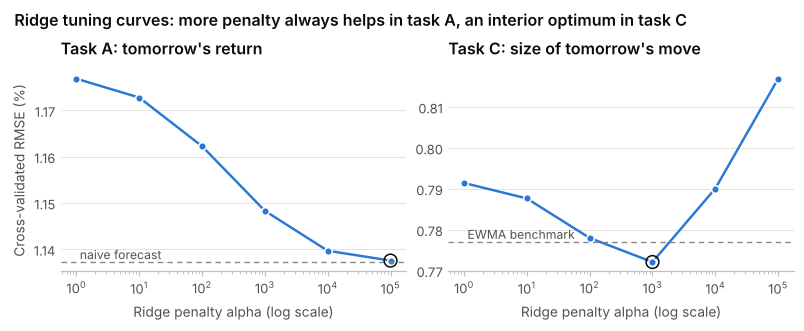

,Task A (return),Task B (direction),Task C (size)
Linear Regression,{},,{}
Ridge,{'model__alpha': 100000},,{'model__alpha': 1000}
Lasso,{'model__alpha': 0.1},,{'model__alpha': 0.03}
Random Forest,"{'max_depth': 2, 'min_samples_leaf': 200}","{'max_depth': 4, 'min_samples_leaf': 100}","{'max_depth': 8, 'min_samples_leaf': 50}"
XGBoost,"{'learning_rate': 0.005, 'max_depth': 1, 'min_child_weight': 100}","{'learning_rate': 0.005, 'max_depth': 2, 'min_child_weight': 100}","{'learning_rate': 0.01, 'max_depth': 3, 'min_child_weight': 100}"
Logistic Regression,,{'model__C': 0.0001},


In [52]:
alphas = REG_GRID["Ridge"][1]["model__alpha"]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), constrained_layout=True)
for ax, search, base, base_label, title in [
        (axes[0], search_A["Ridge"], cv_naive_A, "naive forecast", "Task A: tomorrow's return"),
        (axes[1], search_C["Ridge"], cv_C["EWMA, decay 0.94 (scaled)"], "EWMA benchmark", "Task C: size of tomorrow's move")]:
    scores = -search.cv_results_["mean_test_score"]
    ax.plot(alphas, scores, color=BLUE, marker="o", markersize=5, markeredgecolor="white", markeredgewidth=1)
    ax.axhline(base, color=MUTED, lw=0.9, ls=(0, (4, 3)))
    ax.text(alphas[0], base, f" {base_label}", fontsize=8, color=INK_2, va="bottom")
    best = int(np.argmin(scores))
    ax.scatter([alphas[best]], [scores[best]], s=70, facecolors="none", edgecolors=INK, linewidths=1.0, zorder=4)
    ax.set_xscale("log")
    ax.set_xlabel("Ridge penalty alpha (log scale)")
    ax.set_title(title)
axes[0].set_ylabel("Cross-validated RMSE (%)")
fig.suptitle("Ridge tuning curves: more penalty always helps in task A, an interior optimum in task C",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
save(fig, "fig20_tuning_curves")

tuning = pd.DataFrame({
    "Task A (return)": {n: str(s.best_params_) for n, s in search_A.items()},
    "Task B (direction)": {n: str(s.best_params_) for n, s in search_B.items()},
    "Task C (size)": {n: str(s.best_params_) for n, s in search_C.items()},
}).fillna("")
pd.set_option("display.max_colwidth", 90)
display(tuning)
tuning.to_csv(RES_DIR / "best_hyperparameters.csv")
RESULTS["tuning"] = {"ridge_alphas": alphas,
                     "ridge_cv_A": [float(v) for v in -search_A["Ridge"].cv_results_["mean_test_score"]],
                     "ridge_cv_C": [float(v) for v in -search_C["Ridge"].cv_results_["mean_test_score"]]}

## 6. Results and evaluation

### 6.1 Task A: the features add nothing to a random walk

,CV_RMSE_ret_%,RMSE_$,MAE_$,MAPE_%,R2,RMSE_vs_naive,RMSE_vs_naive_without_30Jan2026,RMSE_vs_drift,DM_vs_naive_p,DM_vs_drift_p
Naive (tomorrow = today),1.1372,37.5995,21.0146,0.7922,0.9977,1.0000,1.0000,1.0023,NaN,NaN
Drift (training mean return),1.1374,37.5164,20.9187,0.7892,0.9977,0.9977,0.9970,1.0000,0.0219,NaN
"ARIMA(1, 0, 1)",NaN,37.5058,21.0056,0.7914,0.9977,0.9980,0.9991,1.0003,0.2366,0.9085
Linear Regression,1.1883,36.9297,21.1164,0.7963,0.9978,0.9946,1.0053,0.9968,0.6222,0.7833
Ridge,1.1376,37.5110,20.9307,0.7894,0.9977,0.9976,0.9974,0.9999,0.0026,0.8904
Lasso,1.1374,37.5164,20.9187,0.7892,0.9977,0.9977,0.9970,1.0000,0.0219,NaN
Random Forest,1.1390,37.5913,20.9975,0.7907,0.9977,0.9990,1.0000,1.0013,0.5413,0.5492
XGBoost,1.1401,37.3877,20.9765,0.7902,0.9977,0.9960,0.9983,0.9983,0.2373,0.6498


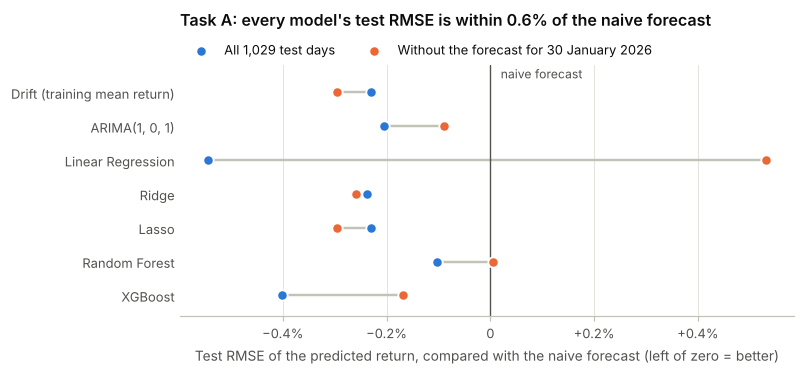

In [53]:
show_A = table_A[["CV_RMSE_ret_%", "RMSE_$", "MAE_$", "MAPE_%", "R2", "RMSE_vs_naive", "RMSE_vs_naive_without_30Jan2026",
                  "RMSE_vs_drift", "DM_vs_naive_p", "DM_vs_drift_p"]]
display(show_A.round(4))

order_A = [n for n in table_A.index if not n.startswith("Naive")]
gap = (table_A.loc[order_A, "RMSE_vs_naive"] - 1) * 100
gap_ex = (table_A.loc[order_A, "RMSE_vs_naive_without_30Jan2026"] - 1) * 100
widest = float(max(gap.abs().max(), gap_ex.abs().max()))
fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
ypos = np.arange(len(order_A))[::-1]
ax.hlines(ypos, gap, gap_ex, color=CONTEXT, lw=1.6, zorder=1)
ax.scatter(gap, ypos, s=46, color=BLUE, edgecolors="white", linewidths=1.2, zorder=3, label="All 1,029 test days")
ax.scatter(gap_ex, ypos, s=46, color=ORANGE, edgecolors="white", linewidths=1.2, zorder=3, label="Without the forecast for 30 January 2026")
ax.axvline(0, color=INK_2, lw=0.9)
ax.text(0.02, len(order_A) - 0.45, "naive forecast", fontsize=8, color=INK_2, va="center")
ax.set_yticks(ypos)
ax.set_yticklabels(order_A)
ax.set_ylim(-0.6, len(order_A) - 0.2)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.1f}%".replace("-", "\u2212") if v else "0"))
ax.set_xlabel("Test RMSE of the predicted return, compared with the naive forecast (left of zero = better)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
ax.set_title(f"Task A: every model's test RMSE is within {np.ceil(widest * 10) / 10:.1f}% of the naive forecast", pad=26)
save(fig, "fig21_task_a_rmse_ratio")
RESULTS["task_a"]["max_gap_vs_naive_pct"] = widest

Linear Regression: total squared-error gain over naive 14.30
  gain on 2026-01-30 alone: 26.79 (187% of the total)
  gain on the other 1028 days together: -12.48
  share of days on which it beat naive: 48.1%
  on that day: actual return -12.07%, predicted -1.17%
Ridge (task C) against EWMA: total gain 27.74; largest single day 11.28 (41%); gain through 2025 10.96; beat EWMA on 54.1% of days
  Diebold-Mariano, Ridge against EWMA, test days through 2025 only: statistic 2.21, p = 0.028
  MAE improvement over EWMA: 2.4% | largest single-day gain falls on 2026-01-30


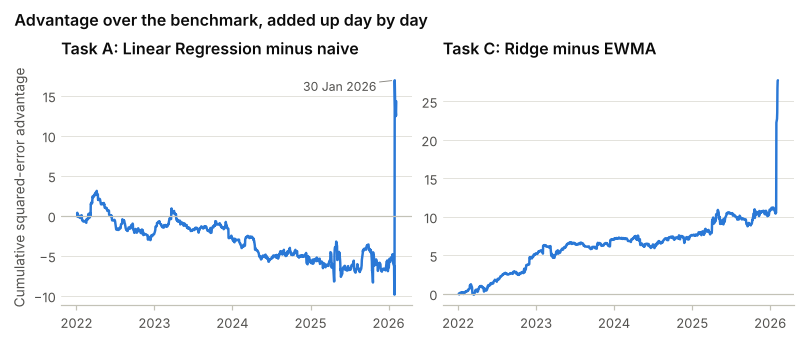

In [54]:
# The "winner" on test RMSE, looked at day by day
winner = best_test_A
sq_naive = y_test_ret.to_numpy() ** 2
gain_A = pd.Series(sq_naive - (y_test_ret.to_numpy() - pred_A[winner]) ** 2, index=test_target_dates)
top_day = gain_A.idxmax()
print(f"{winner}: total squared-error gain over naive {gain_A.sum():.2f}")
print(f"  gain on {top_day.date()} alone: {gain_A.max():.2f} ({gain_A.max() / gain_A.sum():.0%} of the total)")
print(f"  gain on the other {len(gain_A) - 1} days together: {gain_A.sum() - gain_A.max():.2f}")
print(f"  share of days on which it beat naive: {(gain_A > 0).mean():.1%}")
day_row = test.index[test_target_dates == top_day][0]
print(f"  on that day: actual return {y_test_ret[day_row]:.2f}%, predicted {pred_A[winner][list(test.index).index(day_row)]:.2f}%")

best_C = best_cv_C
gain_C = pd.Series(ewma_err ** 2 - (y_test_abs.to_numpy() - pred_C[best_C]) ** 2, index=test_target_dates)
print(f"{best_C} (task C) against EWMA: total gain {gain_C.sum():.2f}; largest single day {gain_C.max():.2f} "
      f"({gain_C.max() / gain_C.sum():.0%}); gain through 2025 {gain_C[gain_C.index < '2026-01-01'].sum():.2f}; "
      f"beat EWMA on {(gain_C > 0).mean():.1%} of days")
err_best_C = y_test_abs.to_numpy() - pred_C[best_C]
dm_C_2025 = dm_test(ewma_err[before_2026], err_best_C[before_2026])
mae_gain_C = 1 - np.mean(np.abs(err_best_C)) / np.mean(np.abs(ewma_err))
print(f"  Diebold-Mariano, {best_C} against EWMA, test days through 2025 only: statistic {dm_C_2025[0]:.2f}, p = {dm_C_2025[1]:.3f}")
print(f"  MAE improvement over EWMA: {mae_gain_C:.1%} | largest single-day gain falls on {gain_C.idxmax().date()}")
RESULTS["fragility"] = {
    "task_c_dm_through_2025_stat": float(dm_C_2025[0]), "task_c_dm_through_2025_p": float(dm_C_2025[1]),
    "task_c_mae_gain_pct": float(mae_gain_C * 100), "task_c_top_day": str(gain_C.idxmax().date()),
    "winner": winner, "total_gain": float(gain_A.sum()), "top_day": str(top_day.date()), "top_day_gain": float(gain_A.max()),
    "gain_other_days": float(gain_A.sum() - gain_A.max()), "share_days_better": float((gain_A > 0).mean() * 100),
    "top_day_actual": float(y_test_ret[day_row]), "top_day_pred": float(pred_A[winner][list(test.index).index(day_row)]),
    "task_c_total_gain": float(gain_C.sum()), "task_c_top_day_gain": float(gain_C.max()),
    "task_c_gain_through_2025": float(gain_C[gain_C.index < "2026-01-01"].sum()), "task_c_share_days_better": float((gain_C > 0).mean() * 100),
}

fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
a.plot(gain_A.index, gain_A.cumsum(), color=BLUE)
a.axhline(0, color=AXIS, lw=0.8)
note(a, "30 Jan 2026", (top_day, gain_A.cumsum()[top_day]), (-12, -4), ha="right")
a.set_title(f"Task A: {winner} minus naive")
a.set_ylabel("Cumulative squared-error advantage")
b.plot(gain_C.index, gain_C.cumsum(), color=BLUE)
b.axhline(0, color=AXIS, lw=0.8)
b.set_title(f"Task C: {best_C} minus EWMA")
for ax in (a, b):
    ax.xaxis.set_major_locator(mpl.dates.YearLocator())
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
fig.suptitle("Advantage over the benchmark, added up day by day", x=0.01, ha="left",
             fontsize=10.5, fontweight="semibold")
save(fig, "fig22_cumulative_advantage")

In [55]:
# Why did the winner predict a fall for that day? Look at the inputs it was given the evening before.
sq_dollar = (test["next_close"] - test["close"]).to_numpy() ** 2
pos = list(test.index).index(day_row)
RESULTS["fragility"].update({
    "top_day_feature_date": str(day_row.date()),
    "naive_day_share_ret_pct": float(sq_naive[pos] / sq_naive.sum() * 100),
    "naive_day_share_usd_pct": float(sq_dollar[pos] / sq_dollar.sum() * 100),
})
print(f"Share of the naive forecast's total squared error that falls on {top_day.date()}: "
      f"{RESULTS['fragility']['naive_day_share_ret_pct']:.1f}% in returns, {RESULTS['fragility']['naive_day_share_usd_pct']:.1f}% in dollars")
winner_model = search_A[winner].best_estimator_ if winner in search_A else None
if winner_model is not None and hasattr(winner_model, "named_steps") and hasattr(winner_model.named_steps["model"], "coef_"):
    scaler_A, coef_A = winner_model.named_steps["scale"], winner_model.named_steps["model"].coef_
    z_day = pd.Series((X_test.loc[day_row].to_numpy() - scaler_A.mean_) / scaler_A.scale_, index=FEATURES)
    z_train_max = ((X_train - scaler_A.mean_) / scaler_A.scale_).abs().max()
    contribution = (z_day * coef_A).sort_values()
    by_size = z_day.reindex(z_day.abs().sort_values(ascending=False).index)
    print(f"Inputs on {day_row.date()}, in standard deviations from their training mean (five largest):")
    print(by_size.head(5).round(2).to_string())
    print(f"Features beyond 3 standard deviations: {int((z_day.abs() > 3).sum())} of {len(FEATURES)} | "
          f"beyond anything in the training years: {int((z_day.abs() > z_train_max).sum())}")
    print("Largest contributions to the predicted return, in percentage points (three most negative, three most positive):")
    print(pd.concat([contribution.head(3), contribution.tail(3)]).round(2).to_string())
    RESULTS["fragility"].update({
        "top_day_z": {k: float(v) for k, v in by_size.head(5).items()},
        "top_day_n_beyond_3sd": int((z_day.abs() > 3).sum()),
        "top_day_n_beyond_training": int((z_day.abs() > z_train_max).sum()),
        "top_day_contributions": {k: float(v) for k, v in pd.concat([contribution.head(3), contribution.tail(3)]).items()},
    })

Share of the naive forecast's total squared error that falls on 2026-01-30: 11.0% in returns, 25.1% in dollars
Inputs on 2026-01-29, in standard deviations from their training mean (five largest):
true_range   8.3300
dist_ma365   4.9100
dist_ma30    4.5600
dist_ma90    4.5100
mom_21       4.0900
Features beyond 3 standard deviations: 13 of 37 | beyond anything in the training years: 5
Largest contributions to the predicted return, in percentage points (three most negative, three most positive):
dist_ma30      -2.4800
true_range     -0.9400
ma30_vs_ma90   -0.9100
mom_21          0.3600
dist_ma7        1.4300
dist_ma90       2.0600


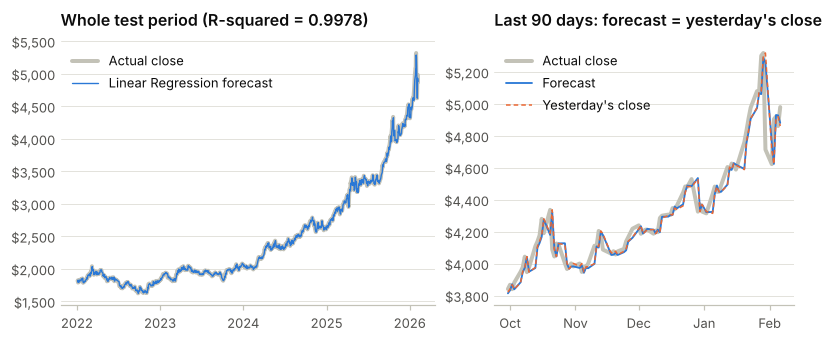

In [56]:
zoom = slice(-90, None)
winner_price = test["close"].to_numpy() * np.exp(pred_A[winner] / 100)
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True, gridspec_kw={"width_ratios": [1.25, 1]})
a.plot(test_target_dates, test["next_close"], color=CONTEXT, lw=2.6, label="Actual close")
a.plot(test_target_dates, winner_price, color=BLUE, lw=0.9, label=f"{winner} forecast")
a.yaxis.set_major_formatter(dollars)
a.xaxis.set_major_locator(mpl.dates.YearLocator())
a.xaxis.set_major_formatter(mpl.dates.DateFormatter("%Y"))
a.legend(loc="upper left")
a.set_title(f"Whole test period (R-squared = {table_A.loc[winner, 'R2']:.4f})")
b.plot(test_target_dates[zoom], test["next_close"].to_numpy()[zoom], color=CONTEXT, lw=2.6, label="Actual close")
b.plot(test_target_dates[zoom], winner_price[zoom], color=BLUE, lw=1.2, label="Forecast")
b.plot(test_target_dates[zoom], test["close"].to_numpy()[zoom], color=ORANGE, lw=1.0, ls=(0, (3, 2)), label="Yesterday's close")
b.yaxis.set_major_formatter(dollars)
b.xaxis.set_major_locator(mpl.dates.MonthLocator())
b.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
b.legend(loc="upper left")
b.set_title("Last 90 days: forecast = yesterday's close")
save(fig, "fig23_actual_vs_predicted")

**Reading the table.**

* Every model, the naive one included, has a price R-squared of 0.998. That number says the price is
  persistent. It says nothing about skill.
* In dollars, the naive forecast misses by $21 on a typical day (MAE) and by $37.60 in RMSE terms, a
  MAPE of 0.79%. The best model improves the MAE by less than half a percent.
* **The drift helps a little.** Adding the average training-period gain of 0.036% a day lowers the test
  RMSE by 0.2%, and the Diebold-Mariano test calls that significant (p = 0.02). The reason is simple:
  gold rose 177% over the test years, so any forecast that leans upward was right more often than not. In
  cross-validation, on folds that include the 2013 to 2015 slide, drift and naive were tied.
* **The features add nothing to the drift.** The tuned models did what the tuning curve said they
  would and shrank toward a constant. Lasso kept none of the 37 features, which makes it the drift forecast
  exactly. Ridge chose the largest penalty on the grid. Random forest and XGBoost chose their shallowest
  trees. No tuned model has an RMSE more than 0.2% below the drift forecast.
* **The apparent winner is an accident.** Linear regression, the only model with no regularisation, has
  the lowest test RMSE (0.5% below naive). It also had the worst cross-validation score, the DM test does
  not call its lead significant, and the day-by-day picture shows why. Its whole advantage, and more,
  comes from the forecast for 30 January 2026, when gold fell 11% and the model happened to be predicting
  a fall of 1.2%. On the other 1,028 days together it did worse than the naive forecast. The inputs on the
  evening of 29 January were far outside the training range (the day's true range was 8 standard
  deviations above its training mean), so that forecast was an extrapolation, and one day cannot tell us
  whether such extrapolations are right in general.
* Dollar errors make the same model look better still ($36.93 against $37.60) because they give more
  weight to days when the price is high. That one day carries a quarter of the naive forecast's squared
  dollar error. The ratio columns are computed on returns for that reason.

So the answer to question 2: only by the long-run drift. With these 37 features, the best forecast of
tomorrow's close is today's close plus about 0.04%.

### 6.2 Task B: direction is a coin flip with a small upward bias

,CV_AUC,accuracy_%,precision_up,recall_up,F1_up,macro_F1,ROC_AUC,predicted_up_%,down_calls,down_calls_right,McNemar_p
Always predict up,NaN,55.5879,0.5559,1.0000,0.7146,0.3573,0.5000,100.0000,0.0000,0.0000,NaN
Logistic Regression,0.5190,55.4908,0.5554,0.9983,0.7138,0.3569,0.5445,99.9028,1.0000,0.0000,1.0000
Random Forest,0.5238,55.0049,0.5623,0.8601,0.6800,0.4611,0.5415,85.0340,154.0000,74.0000,0.6871
XGBoost,0.5246,56.0739,0.5644,0.9196,0.6995,0.4418,0.5284,90.5734,97.0000,51.0000,0.6849


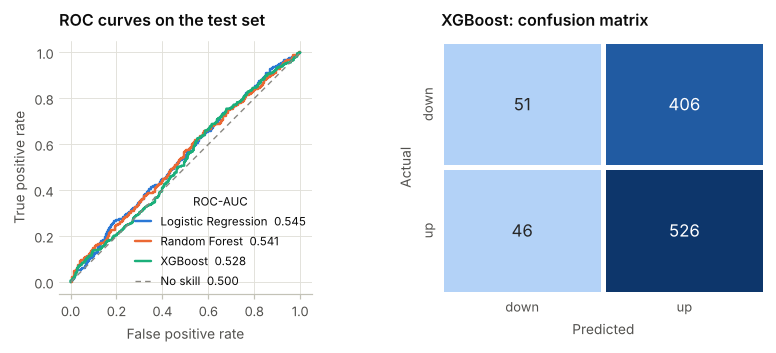

In [57]:
display(table_B.round(4))
best_B = best_cv_B
cm = confusion_matrix(y_test_dir, (proba_B[best_B] > 0.5).astype(int))
fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.1), constrained_layout=True, gridspec_kw={"width_ratios": [1.25, 1]})
for name, color in zip(search_B, [BLUE, ORANGE, AQUA]):
    fpr, tpr, _ = roc_curve(y_test_dir, proba_B[name])
    a.plot(fpr, tpr, color=color, lw=1.6, label=f"{name}  {table_B.loc[name, 'ROC_AUC']:.3f}")
a.plot([0, 1], [0, 1], color=MUTED, lw=0.9, ls=(0, (4, 3)), label="No skill  0.500")
a.set_xlabel("False positive rate")
a.set_ylabel("True positive rate")
a.set_aspect("equal")
a.grid(axis="x")
a.legend(loc="lower right", fontsize=7.6, title="ROC-AUC", title_fontsize=7.6, handlelength=1.4, borderaxespad=0.1)
a.set_title("ROC curves on the test set")
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQUENTIAL, cbar=False, linewidths=2, linecolor="white", ax=b,
            annot_kws={"size": 11}, xticklabels=["down", "up"], yticklabels=["down", "up"], vmin=0)
b.set_xlabel("Predicted")
b.set_ylabel("Actual")
b.tick_params(length=0)
b.set_title(f"{best_B}: confusion matrix")
save(fig, "fig24_task_b_roc_confusion")
RESULTS["task_b"]["confusion_best"] = cm.tolist()

Gold closed higher on 55.6% of test days, so a "model" that always says up scores 55.6% without looking
at any data. The three classifiers score between 55.0% and 56.1%. Their ROC-AUC values are 0.53 to 0.54,
where 0.50 is no skill. McNemar's test asks whether a model is right more often than wrong on the days it
disagrees with "always up". XGBoost, the model cross-validation preferred, called 97 down days and was
right on 51 of them, which is what a coin would do (p = 0.68).

The F1 column is a warning about metrics. "Always up" has the best F1 for the up class (0.71) because its
recall is 1.0, and one of the worst macro-F1 scores (0.36) because it never finds a down day. On this task
a high F1 for one class only means the model says "up" a lot.

The answer to question 3 is no.

### 6.3 Task C: the size of the move can be predicted

,CV_RMSE_%,RMSE_%,MAE_%,R2_vs_training_mean_%,R2_through_2025_%,Spearman,DM_vs_EWMA_statistic,DM_vs_EWMA_p
Training mean,0.8256,0.8082,0.5485,0.0000,0.0000,NaN,-1.8858,0.0596
Volatility_30d (scaled),0.7831,0.7897,0.5407,4.5131,0.8316,0.1571,-2.5770,0.0101
"EWMA, decay 0.94 (scaled)",0.7771,0.7787,0.5401,7.1558,4.0783,0.1576,NaN,NaN
Linear Regression,0.8109,0.7423,0.5267,15.6417,7.3048,0.2250,1.6692,0.0954
Ridge,0.7721,0.7612,0.5272,11.2835,6.3522,0.2124,2.1662,0.0305
Lasso,0.7734,0.7765,0.5299,7.6826,5.8245,0.1776,0.3561,0.7219
Random Forest,0.7815,0.7797,0.5443,6.9275,3.8017,0.1724,-0.1371,0.8910
XGBoost,0.7820,0.7765,0.5433,7.6958,3.7340,0.1658,0.3158,0.7522


,predicted,realised,share_above_1pct_%
Q1\nsmallest,0.5550,0.5830,17.4760
Q2,0.6680,0.6570,22.8160
Q3,0.7450,0.7590,31.2200
Q4,0.8360,0.7820,28.1550
Q5\nlargest,1.1400,1.1800,43.2040


Share of test days with a move above 1%: 28.6%
AUC for spotting those days: Ridge 0.622 | EWMA 0.591 | (direction, XGBoost: 0.528)


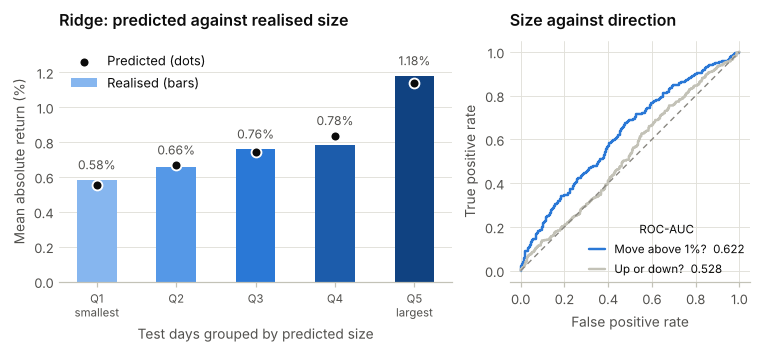

In [58]:
display(table_C.round(4))

pred_best_C = pred_C[best_C]
qbin = pd.qcut(pred_best_C, 5, labels=False)
calib = pd.DataFrame({"predicted": pd.Series(pred_best_C).groupby(qbin).mean(),
                      "realised": pd.Series(y_test_abs.to_numpy()).groupby(qbin).mean(),
                      "share_above_1pct_%": pd.Series(y_test_abs.to_numpy() > 1).groupby(qbin).mean() * 100})
calib.index = ["Q1\nsmallest", "Q2", "Q3", "Q4", "Q5\nlargest"]
display(calib.round(3))
calib.to_csv(RES_DIR / "task_c_calibration.csv")

big = (y_test_abs.to_numpy() > 1).astype(int)
auc_size = roc_auc_score(big, pred_best_C)
auc_size_ewma = roc_auc_score(big, pred_C["EWMA, decay 0.94 (scaled)"])
auc_dir = table_B.loc[best_B, "ROC_AUC"]
print(f"Share of test days with a move above 1%: {big.mean():.1%}")
print(f"AUC for spotting those days: {best_C} {auc_size:.3f} | EWMA {auc_size_ewma:.3f} | (direction, {best_B}: {auc_dir:.3f})")
RESULTS["task_c"].update({
    "calibration": {"predicted": [float(v) for v in calib["predicted"]], "realised": [float(v) for v in calib["realised"]],
                    "share_above_1": [float(v) for v in calib["share_above_1pct_%"]]},
    "big_move_share": float(big.mean() * 100), "auc_size": float(auc_size), "auc_size_ewma": float(auc_size_ewma),
})

fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 3.1), constrained_layout=True, gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(5)
a.bar(x, calib["realised"], width=0.5, color=["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"], label="Realised (bars)")
a.scatter(x, calib["predicted"], s=42, color=INK, edgecolors="white", linewidths=1.2, zorder=3, label="Predicted (dots)")
for i, (v, p_) in enumerate(zip(calib["realised"], calib["predicted"])):
    a.text(i, max(v, p_) + 0.045, f"{v:.2f}%", ha="center", va="bottom", fontsize=8, color=INK_2)
a.set_ylim(0, 1.38)
a.set_xticks(x)
a.set_xticklabels(calib.index, fontsize=7.5)
a.set_ylabel("Mean absolute return (%)")
a.set_xlabel("Test days grouped by predicted size")
a.legend(loc="upper left")
a.set_title(f"{best_C}: predicted against realised size")
fpr, tpr, _ = roc_curve(big, pred_best_C)
b.plot(fpr, tpr, color=BLUE, lw=1.6, label=f"Move above 1%?  {auc_size:.3f}")
fpr, tpr, _ = roc_curve(y_test_dir, proba_B[best_B])
b.plot(fpr, tpr, color=CONTEXT, lw=1.6, label=f"Up or down?  {auc_dir:.3f}")
b.plot([0, 1], [0, 1], color=MUTED, lw=0.9, ls=(0, (4, 3)))
b.set_xlabel("False positive rate")
b.set_ylabel("True positive rate")
b.set_aspect("equal")
b.grid(axis="x")
b.legend(loc="lower right", fontsize=7.6, title="ROC-AUC", title_fontsize=7.6, handlelength=1.4, borderaxespad=0.1)
b.set_title("Size against direction")
save(fig, "fig25_task_c_calibration")

,mean_rise_%,std
Recent returns,0.1240,0.0960
Momentum,-0.0840,0.1000
Trend (moving averages),1.6500,0.3230
Volatility,6.2460,0.6640
Oscillators,0.0640,0.1720
Calendar,0.3920,0.1530


,standardised coefficient
atr_14,0.0909
true_range,0.0599
abs_ret_1,-0.0584
vol_90,0.0501
drawdown_252,-0.0496
vol_30,0.0441
dow_wed,0.0368
dist_ma365,0.0298


Correlation between true_range and abs_ret_1 in the training years: 0.83


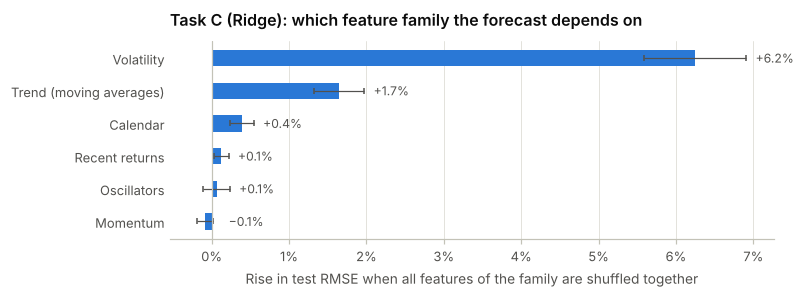

In [59]:
def family_importance(estimator, y_true, repeats=30):
    """Shuffle all features of one family together and record how much the test RMSE rises (in %)."""
    base = np.sqrt(mean_squared_error(y_true, estimator.predict(X_test)))
    perm_rng = np.random.default_rng(SEED)
    rows = {}
    for family, cols in FAMILIES.items():
        rises = []
        for _ in range(repeats):
            shuffled = X_test.copy()
            shuffled[cols] = X_test[cols].to_numpy()[perm_rng.permutation(len(X_test))]
            rises.append(np.sqrt(mean_squared_error(y_true, estimator.predict(shuffled))) / base * 100 - 100)
        rows[family] = {"mean_rise_%": np.mean(rises), "std": np.std(rises)}
    return pd.DataFrame(rows).T


imp_C = family_importance(search_C[best_C].best_estimator_, y_test_abs)
display(imp_C.round(3))
imp_C.to_csv(RES_DIR / "family_importance.csv")

coefs_C = None
if hasattr(search_C[best_C].best_estimator_, "named_steps"):
    coefs_C = pd.Series(search_C[best_C].best_estimator_.named_steps["model"].coef_, index=FEATURES).sort_values(key=np.abs, ascending=False)
    display(coefs_C.head(8).round(4).to_frame("standardised coefficient"))
RESULTS["importance"] = {
    "task_c": {k: float(v) for k, v in imp_C["mean_rise_%"].items()}, "task_c_model": best_C,
    "task_c_top_coefs": None if coefs_C is None else {k: float(v) for k, v in coefs_C.head(8).items()},
}
RESULTS["importance"]["corr_true_range_abs_ret"] = float(X_train["true_range"].corr(X_train["abs_ret_1"]))
print("Correlation between true_range and abs_ret_1 in the training years:", round(RESULTS["importance"]["corr_true_range_abs_ret"], 2))

order_f = imp_C["mean_rise_%"].sort_values().index
fig, ax = plt.subplots(figsize=(7.2, 2.6), constrained_layout=True)
ax.barh(range(len(order_f)), imp_C.loc[order_f, "mean_rise_%"], xerr=imp_C.loc[order_f, "std"], height=0.5, color=BLUE,
        error_kw=dict(ecolor=INK_2, elinewidth=0.8, capsize=2))
for i, f_ in enumerate(order_f):
    v = imp_C.loc[f_, "mean_rise_%"]
    ax.text(max(v, 0) + imp_C.loc[f_, "std"] + 0.12, i, f"{v:+.1f}%".replace("-", "\u2212"), va="center", fontsize=8, color=INK_2)
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_yticks(range(len(order_f)))
ax.set_yticklabels(order_f)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Rise in test RMSE when all features of the family are shuffled together")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title(f"Task C ({best_C}): which feature family the forecast depends on")
save(fig, "fig26_family_importance")

Here the models have something to learn.

* The ridge model chosen by cross-validation explains 11% of the test variance in the size of the move.
  `Volatility_30d` on its own explains under 5% and the EWMA 7%. The Diebold-Mariano test puts ridge
  ahead of the EWMA at the 5% level (p = 0.03).
* We applied the same day-by-day check as in task A. About 40% of ridge's squared-error lead over the
  EWMA comes from 30 January 2026, so the 11% flatters it. The lead does not vanish without 2026, though.
  Through the end of 2025 it rises steadily, ridge explains 6.4% against the EWMA's 4.1%, and the DM test
  on those days alone still favours ridge (p = 0.03). Ridge beat the EWMA on 54% of all test days.
* Measures that one day cannot move agree. The rank correlation between predicted and realised size is
  0.21 for ridge and 0.16 for the EWMA. Test days in ridge's top fifth by predicted size moved twice as
  much as days in its bottom fifth, and predicted and realised averages are close in every group.
* Shuffling the volatility family raises the error by 6%, far more than any other family. In task A there
  is nothing to rank, because the tuned Lasso set all 37 coefficients to zero.

Plain linear regression scores better on the test set than ridge. We still report ridge as our model,
because it is the one cross-validation chose without reference to the test set, and linear regression
had the worst cross-validated error of the five.

### 6.4 Putting A and C together: a price forecast with an honest band

Task A says the best point forecast is today's close. Task C says how wide the uncertainty around it
should be. Together they give a 95% band for tomorrow's close:

`Close(t) x exp(-k x predicted size / 100)` to `Close(t) x exp(+k x predicted size / 100)`

The multiplier `k` is set so that 95% of training days fall inside the band. To keep that calibration
honest we use out-of-fold predictions from the same five folds, never predictions on data the model was
fitted on. We compare three bands: a constant width, an EWMA-scaled width, and the ridge-scaled width.

In [60]:
model_C = search_C[best_C].best_estimator_
FLOOR = 0.10                                         # predicted size is not allowed below 0.10%
oof = pd.Series(np.nan, index=train.index)
for tr, va in tscv.split(X_train):
    oof.iloc[va] = clone(model_C).fit(X_train.iloc[tr], y_train_abs.iloc[tr]).predict(X_train.iloc[va])
has_oof = oof.notna()
ewma_train = bench_C["EWMA, decay 0.94 (scaled)"].reindex(train.index)

k_constant = float(y_train_abs[has_oof].quantile(0.95))
k_ewma = float((y_train_abs[has_oof] / ewma_train[has_oof]).quantile(0.95))
k_model = float((y_train_abs[has_oof] / oof[has_oof].clip(lower=FLOOR)).quantile(0.95))
print(f"Calibration rows: {int(has_oof.sum())} | constant half-width {k_constant:.2f}% | k for EWMA {k_ewma:.2f} | k for {best_C} {k_model:.2f} "
      f"| normal-theory k would be {1.96 * np.sqrt(np.pi / 2):.2f}")

half_width = {
    "Constant width": np.full(len(test), k_constant),
    "EWMA-scaled": k_ewma * pred_C["EWMA, decay 0.94 (scaled)"],
    f"{best_C}-scaled": k_model * np.clip(pred_best_C, FLOOR, None),
}
actual_abs = y_test_abs.to_numpy()
years = pd.Series(test_target_dates.year, index=test.index)


def band_scores(h):
    inside = actual_abs <= h
    interval_score = 2 * h + (2 / 0.05) * np.clip(actual_abs - h, 0, None)       # Winkler score, lower is better
    dollars_wide = test["close"].to_numpy() * (np.exp(h / 100) - np.exp(-h / 100))
    out = {"coverage_%": inside.mean() * 100, "mean_half_width_%": h.mean(), "mean_width_$": dollars_wide.mean(),
           "interval_score": interval_score.mean()}
    out.update({f"coverage_{y}_%": inside[(years == y).to_numpy()].mean() * 100 for y in sorted(years.unique())})
    return out


band_table = pd.DataFrame({name: band_scores(h) for name, h in half_width.items()}).T
display(band_table.round(2))
band_table.to_csv(RES_DIR / "prediction_bands.csv")
days_per_year = years.value_counts().sort_index()
cov_cols = [c for c in band_table.columns if c.startswith("coverage_2")]
RESULTS["bands"] = {
    "k_constant": k_constant, "k_ewma": k_ewma, "k_model": k_model, "k_normal": float(1.96 * np.sqrt(np.pi / 2)),
    "calibration_rows": int(has_oof.sum()), "floor": FLOOR, "model": best_C,
    "table": {k: {c: float(v) for c, v in row.items()} for k, row in band_table.to_dict("index").items()},
    "days_per_year": {int(k): int(v) for k, v in days_per_year.items()},
    "coverage_spread": {name: float(band_table.loc[name, cov_cols].max() - band_table.loc[name, cov_cols].min()) for name in band_table.index},
}

Calibration rows: 4155 | constant half-width 2.29% | k for EWMA 2.69 | k for Ridge 2.68 | normal-theory k would be 2.46


,coverage_%,mean_half_width_%,mean_width_$,interval_score,coverage_2022_%,coverage_2023_%,coverage_2024_%,coverage_2025_%,coverage_2026_%
Constant width,94.8500,2.2900,112.1700,6.2600,97.2000,97.2000,96.4300,90.8700,72.0000
EWMA-scaled,94.7500,2.1500,112.3900,5.7600,94.8000,94.8000,95.6300,94.4400,88.0000
Ridge-scaled,94.6600,2.1200,110.8600,5.5700,93.2000,94.0000,96.0300,96.0300,88.0000


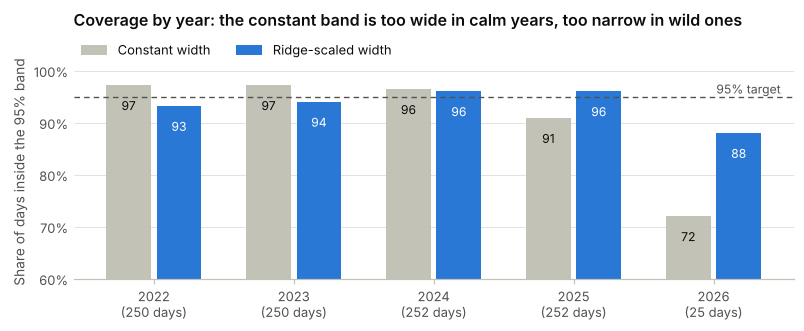

In [61]:
adaptive = f"{best_C}-scaled"
fig, ax = plt.subplots(figsize=(7.2, 2.9), constrained_layout=True)
yr = sorted(years.unique())
w = 0.32
ax.bar(np.arange(len(yr)) - w / 2 - 0.02, [band_table.loc["Constant width", f"coverage_{y}_%"] for y in yr], width=w, color=CONTEXT, label="Constant width")
ax.bar(np.arange(len(yr)) + w / 2 + 0.02, [band_table.loc[adaptive, f"coverage_{y}_%"] for y in yr], width=w, color=BLUE, label=f"{best_C}-scaled width")
ax.axhline(95, color=INK_2, lw=0.9, ls=(0, (4, 3)))
ax.text(len(yr) - 0.52, 95.6, "95% target", fontsize=8, color=INK_2, ha="right")
for i, y in enumerate(yr):
    for dx, name in [(-w / 2 - 0.02, "Constant width"), (w / 2 + 0.02, adaptive)]:
        v = band_table.loc[name, f"coverage_{y}_%"]
        ax.text(i + dx, v - 2.5, f"{v:.0f}", ha="center", va="top", fontsize=8, color="white" if name == adaptive else INK)
ax.set_xticks(range(len(yr)))
ax.set_xticklabels([f"{y}\n({days_per_year[y]} days)" for y in yr])
ax.set_ylim(60, 101)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Share of days inside the 95% band")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
ax.set_title("Coverage by year: the constant band is too wide in calm years, too narrow in wild ones", pad=26)
save(fig, "fig27_band_coverage_by_year")

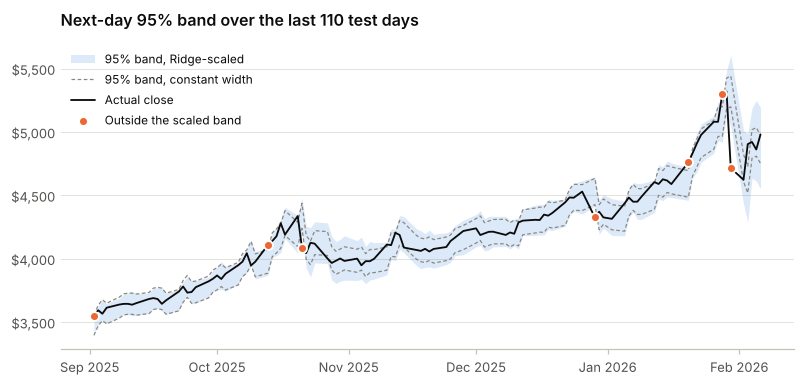

Scaled half-width ranges from 1.03% (band for 2023-08-30) to 7.53% (band for 2026-02-03) over the test period
Days outside the band in the last 110: scaled 7, constant 17


In [62]:
last = slice(-110, None)
h = half_width[adaptive][last]
c_t = test["close"].to_numpy()[last]
dates = test_target_dates[last]
actual = test["next_close"].to_numpy()[last]
lo, hi = c_t * np.exp(-h / 100), c_t * np.exp(h / 100)
lo_c, hi_c = c_t * np.exp(-k_constant / 100), c_t * np.exp(k_constant / 100)
outside = (actual < lo) | (actual > hi)
fig, ax = plt.subplots(figsize=(7.2, 3.4), constrained_layout=True)
ax.fill_between(dates, lo, hi, color=BLUE, alpha=0.16, linewidth=0, label=f"95% band, {best_C}-scaled")
ax.plot(dates, lo_c, color=MUTED, lw=0.8, ls=(0, (3, 2)), label="95% band, constant width")
ax.plot(dates, hi_c, color=MUTED, lw=0.8, ls=(0, (3, 2)))
ax.plot(dates, actual, color=INK, lw=1.2, label="Actual close")
ax.scatter(dates[outside], actual[outside], s=34, color=ORANGE, edgecolors="white", linewidths=1.2, zorder=4, label="Outside the scaled band")
ax.yaxis.set_major_formatter(dollars)
ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", fontsize=7.8)
ax.set_title("Next-day 95% band over the last 110 test days")
save(fig, "fig28_prediction_band")
RESULTS["bands"]["last110_outside"] = int(outside.sum())
RESULTS["bands"]["last110_outside_constant"] = int(((actual < lo_c) | (actual > hi_c)).sum())
RESULTS["bands"]["width_range_pct"] = [float(half_width[adaptive].min()), float(half_width[adaptive].max())]
h_all = pd.Series(half_width[adaptive], index=test_target_dates)
RESULTS["bands"]["narrowest_day"] = str(h_all.idxmin().date())
RESULTS["bands"]["widest_day"] = str(h_all.idxmax().date())
RESULTS["bands"]["misses_2026"] = int((actual_abs > half_width[adaptive])[(years == 2026).to_numpy()].sum())
print(f"Scaled half-width ranges from {half_width[adaptive].min():.2f}% (band for {h_all.idxmin().date()}) "
      f"to {half_width[adaptive].max():.2f}% (band for {h_all.idxmax().date()}) over the test period")
print(f"Days outside the band in the last 110: scaled {int(outside.sum())}, constant {int(((actual < lo_c) | (actual > hi_c)).sum())}")

All three bands cover close to 95% of test days overall, so on the headline number they look the same.
The difference is *when* they miss. The constant band covers 96 to 97% of days in 2022 to 2024, which
means it is wider than it needs to be, then drops to 91% in 2025 and 72% in early 2026, when a user
needs it most. The scaled band stays between 93% and 96% in every full year. It cannot see a shock
coming (both 29 and 30 January 2026 fall outside it), but it widens within days, so the sessions after a
big move are covered. Over the last 110 test days it misses 7 times where the constant band misses 17.

Its interval score, which rewards narrow bands and punishes misses, is the lowest of the three (5.57).
The EWMA-scaled band is close behind (5.76) and needs no model at all, so most of the benefit comes
from scaling the band by recent volatility in the first place.

### 6.5 Would retraining during the test period have helped?

The models above were fitted once, on data to the end of 2021. A fair objection is that a real user would
keep retraining. We refit the tuned models every 63 trading days (about a quarter) on all data up to that
point and compare.

In [63]:
def walk_forward(estimator, target, step=63):
    X_all, y_all = model_df[FEATURES], model_df[target]
    n0 = len(train)
    out = np.empty(len(test))
    for s in range(0, len(test), step):
        fitted = clone(estimator).fit(X_all.iloc[: n0 + s], y_all.iloc[: n0 + s])
        out[s: s + step] = fitted.predict(X_all.iloc[n0 + s: n0 + s + step])
    return out


rmse = lambda y, p: float(np.sqrt(np.mean((np.asarray(y) - p) ** 2)))
wf_rows = {}
for task, target, searches, y_true in [("A", "y_ret", search_A, y_test_ret), ("C", "y_abs", search_C, y_test_abs)]:
    for name in ["Ridge", "XGBoost"]:
        static = searches[name].predict(X_test)
        rolling = walk_forward(searches[name].best_estimator_, target)
        wf_rows[f"Task {task}, {name}"] = {"fitted_once_RMSE": rmse(y_true, static), "refitted_quarterly_RMSE": rmse(y_true, rolling)}
wf_table = pd.DataFrame(wf_rows).T
wf_table["change_%"] = (wf_table["refitted_quarterly_RMSE"] / wf_table["fitted_once_RMSE"] - 1) * 100
display(wf_table.round(4))
wf_table.to_csv(RES_DIR / "walk_forward.csv")
RESULTS["walk_forward"] = {k: {c: float(v) for c, v in row.items()} for k, row in wf_table.to_dict("index").items()}
RESULTS["walk_forward"]["naive_rmse"] = float(np.sqrt(np.mean(y_test_ret.to_numpy() ** 2)))

,fitted_once_RMSE,refitted_quarterly_RMSE,change_%
"Task A, Ridge",1.1289,1.1286,-0.0260
"Task A, XGBoost",1.1271,1.1266,-0.0383
"Task C, Ridge",0.7612,0.7587,-0.3254
"Task C, XGBoost",0.7765,0.7711,-0.6901


Retraining every quarter changes the test RMSE by less than one percent. The task A models still sit on
the drift forecast (RMSE 1.129), so the result in 6.1 is not caused by a stale model.

## 7. Conclusions

**What we found**

1. *The data needed more cleaning than its name suggests.* Seven of 20 columns are redundant, 430 early
   rows have a close outside the day's own range, 12.7% of bars are flat, the rolling windows are counted
   in trading days, and volume follows the contract calendar. Every missing value is a rolling-window
   warm-up. Close itself checks out against press reports to within 10 cents.
2. *Gold rose 18-fold in 25 years, with fat-tailed daily returns and clustered volatility.* Big days are
   about five times as common as a normal distribution predicts.
3. *Tomorrow's price cannot be predicted better than "today's price plus the long-run drift".* All
   eight forecasts finish within 0.6% of the naive one (RMSE of returns), the 37 features add nothing to the drift, and
   the model that looks best owes its lead to a single day.
4. *Tomorrow's direction cannot be predicted either.* Three classifiers score 55.0 to 56.1% against a
   55.6% base rate.
5. *The size of tomorrow's move can be predicted in part.* That turns the naive forecast into something
   usable: a 95% band whose coverage stays between 93% and 96% in each full test year.

**Limitations.** We only used the price history of one futures series. Interest rates, the dollar,
inflation and central-bank buying are not in the file. The series is the front-month contract, so it
carries small jumps when contracts roll, and its Open, High and Low are unreliable in the early years. The test
period is one particular stretch of history, with an exceptional rally and crash in it.

**Future work.** Add macro variables and test whether they help at weekly or monthly horizons, where
trends may be easier to find than at one day. Replace the EWMA and ridge volatility models with GARCH
or a realised-volatility model on intraday data. Check the bands on another metal.

In [64]:
def to_builtin(obj):
    if isinstance(obj, dict):
        return {str(k): to_builtin(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_builtin(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, float) and np.isnan(obj):
        return None
    return obj


RESULTS["environment"] = {
    "python": __import__("platform").python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scikit_learn": __import__("sklearn").__version__, "statsmodels": __import__("statsmodels").__version__,
    "xgboost": __import__("xgboost").__version__, "scipy": __import__("scipy").__version__,
    "matplotlib": mpl.__version__, "seaborn": sns.__version__, "seed": SEED,
}
with open(RES_DIR / "metrics.json", "w") as fh:
    json.dump(to_builtin(RESULTS), fh, indent=2)
print("Saved", len(list(FIG_DIR.glob('*.png'))), "figures and", len(list(RES_DIR.glob('*'))), "result files.")
print(RESULTS["environment"])

Saved 28 figures and 30 result files.
{'python': '3.13.18', 'pandas': '3.0.5', 'numpy': '2.5.3', 'scikit_learn': '1.9.1', 'statsmodels': '0.15.0', 'xgboost': '3.4.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'seed': 42}
